<a href="https://colab.research.google.com/github/Suhrobjonibodullayev/ML-Learning-Journey/blob/main/06_Deep_Learning_besics/Deep_Learning_besics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Perseptron - bu sun'iy intellekt olamidagi eng sodda bitta sun'iy neyron (miya hujayrasi). U kompyuterga bir nechta ma'lumotni ko'rib chiqib, bitta aniq qaror qabul qilishni (masalan: "Ha" yoki "Yo'q",)

sen bugun do'stlaring bilan ko'chada futbol o'ynash yoki o'ynamaslik haqida qaror qabul qilishing kerak.

Miyang qanday ishlaydi?

Qaror qabul qilishda bir nechta shartlarni tekshirasan:

x1 — Havo quyoshlimi? (1 = ha, 0 = yo'q)

x2 — Darsing kammi? (1 = ha, 0 = yo'q)

x3 — Eng yaqin do'sting boradimi? (1 = ha, 0 = yo'q)

Lekin bu shartlarning hammasi bir xil darajada muhim emas. Masalan, havo yomon bo'lsa ham darsing bo'lmasa o'ynashing mumkin, lekin darsing juda ko'p bo'lsa — boshqa omillar ahamiyatsiz bo'lib qoladi.

Har bir shartning sen uchun o'z ahamiyati (vazni — w) bor. Perseptron aynan shu tarzda fikrlaydi.

Perseptronning 4 ta asosiy qismi:

1. Kirishlar (x1,x2,x3,...): Tizimga kirib kelayotgan ma'lumotlar (bizning misolda: havo, dars, do'st).
2. Vaznlar (w1,w2,w3...): Har bir kirishning qanchalik muhimligini ko'rsatuvchi sonlar. Agar biror narsa juda muhim bo'lsa, uning vazni katta bo'ladi.
3. Siljish (Bias — b): Sening ichki moyilliging. Masalan, sen umuman olganda futbolni juda yaxshi ko'rasanmi yoki dangasaroqmisan? Bu qaror qabul qilish chegarasini oldinga yoki orqaga suradi.
4. Aktivatsiya funksiyasi (Activation Function): Chiqqan yakuniy ballga qarab "Ha" (1) yoki "Yo'q" (0) chirog'ini yoquvchi tugma.

1-qadam: Umumiy ballni hisoblash (Og'irlikli yig'indi)
Har bir kiruvchi ma'lumot o'zining vazniga ko'paytiriladi va barchasi qo'shilib, unga siljish (b) qo'shiladi: z = (x1 * w1) + (x2 * w2) + .... + b

2-qadam: Qaror chiqarish (Pog'onali aktivatsiya)

Olingan z soni 0 dan katta yoki teng bo'lsa, javob — 1 ("Ha, boraman!").Agar 0 dan kichik bo'lsa, javob — 0 ("Yo'q, uyda qolaman"):

In [32]:
import numpy as np

w = np.array([2, -3])      # vaznlar
b = -4                     # bias

def neyron(x):
    z = np.dot(x, w) + b
    return int(z > 0)

print(neyron([5, 1]))
print(neyron([3, 2]))

1
0


🧠 Perseptron: Mantiqiy Eshiklar (AND, OR, NAND)

Perseptron qaror qabul qilish uchun quyidagi 2 bosqichli formuladan foydalanadi:

1. **Og'irlikli yig'indi ($z$):**
   $$z = w_1 x_1 + w_2 x_2 + b$$
2. **Aktivatsiya (Step Function — $\hat{y}$):**
   $$\hat{y} = \begin{cases} 1, & \text{agar } z \ge 0 \\ 0, & \text{agar } z < 0 \end{cases}$$

---

 1. AND (VA) Eshigi

> Faqat ikkala kirish ham $1$ bo'lgandagina chiqish $1$ bo'ladi.

* **Parametrlar:** $w_1 = 1$, $w_2 = 1$, $b = -1.5$
* **Hisoblash formulasi:** $z = 1 \cdot x_1 + 1 \cdot x_2 - 1.5$

 2. OR (YOKI) Eshigi

> Kamida bitta kirish $1$ bo'lsa, chiqish $1$ bo'ladi.

* **Parametrlar:** $w_1 = 1$, $w_2 = 1$, $b = -0.5$
* **Hisoblash formulasi:** $z = 1 \cdot x_1 + 1 \cdot x_2 - 0.5$


 3. NAND (NOT-AND / VA-EMAS) Eshigi

> AND eshigining teskarisi: faqat ikkala kirish $1$ bo'lganda chiqish $0$, qolgan barcha holatlarda $1$ bo'ladi.

* **Parametrlar:** $w_1 = -1$, $w_2 = -1$, $b = 1.5$
* **Hisoblash formulasi:** $z = -1 \cdot x_1 - 1 \cdot x_2 + 1.5$


In [33]:
import numpy as np

X = np.array([[0,0],[0,1],[1,0],[1,1]])

def eshik(w, b):
    return (X @ np.array(w) + b > 0).astype(int)

print("AND ", eshik([2, 2], -3))
print("OR  ", eshik([2, 2], -1))
print("NAND", eshik([-2, -2], 3))

AND  [0 0 0 1]
OR   [0 1 1 1]
NAND [1 1 1 0]


In [34]:
import numpy as np

# 1. Umumiy perseptron funksiyasi
def perceptron(x, w, b):
    """
    x: kirish signallari (numpy array yoki ro'yxat)
    w: vaznlar (numpy array)
    b: siljish (bias)
    """
    # z = w1*x1 + w2*x2 + b (vektor ko'paytmasi orqali hisoblash)
    z = np.dot(x, w) + b

    # Step aktivatsiya funksiyasi: agar z >= 0 bo'lsa 1, aks holda 0
    return np.where(z >= 0, 1, 0)

# 2. Mantiqiy eshiklar funksiyalari
def AND_gate(x):
    w = np.array([1.0, 1.0])
    b = -1.5
    return perceptron(x, w, b)

def OR_gate(x):
    w = np.array([1.0, 1.0])
    b = -0.5
    return perceptron(x, w, b)

def NAND_gate(x):
    w = np.array([-1.0, -1.0])
    b = 1.5
    return perceptron(x, w, b)

# 3. Sinov ma'lumotlari (barcha 4 ta kombinatsiya)
inputs = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

# 4. Natijalarni chiroyli jadval ko'rinishida chiqarish
print("x1  x2 | AND | OR  | NAND")
print("-" * 25)
for x in inputs:
    res_and = AND_gate(x)
    res_or = OR_gate(x)
    res_nand = NAND_gate(x)
    print(f" {x[0]}   {x[1]}  |  {res_and}  |  {res_or}  |  {res_nand}")

x1  x2 | AND | OR  | NAND
-------------------------
 0   0  |  0  |  0  |  1
 0   1  |  0  |  1  |  1
 1   0  |  0  |  1  |  1
 1   1  |  1  |  1  |  0


📈 Perseptronning O'rganish Qoidasi (Perceptron Learning Rule)

Perseptron o'rganish algoritmining maqsadi — ma'lumotlar to'plamidagi xatolarni tahlil qilib, to'g'ri chiziqli ajratuvchi **vaznlar ($w$)** va **siljish ($b$)** parametrlarini avtomatik topishdir.

---

1. Asosiy Formulalar

Har bir o'rganish qadamida (har bir namuna uchun) hisob-kitob quyidagicha bajariladi:

 1-qadam: Bashorat qilish
$$z = \sum_{i=1}^{n} w_i x_i + b$$

$$\hat{y} = \begin{cases} 1, & \text{agar } z \ge 0 \\ 0, & \text{agar } z < 0 \end{cases}$$

2-qadam: Xatoni aniqlash
$$e = y - \hat{y}$$

* $y$ — namunaning haqiqiy (kutilgan) qiymati ($0$ yoki $1$)
* $\hat{y}$ — perseptron hisoblagan model javobi ($0$ yoki $1$)

3-qadam: Vaznlar va siljishni yangilash
Vaznlar va siljish o'zgarish miqdori ($\Delta$) orqali yangilanadi:

$$\Delta w_i = \eta \cdot (y - \hat{y}) \cdot x_i$$
$$\Delta b = \eta \cdot (y - \hat{y})$$

Parametrlarni yangi qiymatga o'tkazish:

$$w_i \leftarrow w_i + \Delta w_i$$
$$b \leftarrow b + \Delta b$$

* $\eta$ (*eta* — Learning Rate): O'rganish tezligi ($0 < \eta \le 1$). Qadam kattaligini belgilaydi.
* $x_i$: Kiruvchi $i$-signal qiymati. Agar $x_i = 0$ bo'lsa, xatoga ta'sir qilmagani uchun mos $w_i$ o'zgarmaydi.

---

2. Xatolik Holatlari Tahlili

| Kutilgan ($y$) | Bashorat ($\hat{y}$) | Xato ($y - \hat{y}$) | Olingan xulosa | Parametrlar o'zgarishi |
| :---: | :---: | :---: | :--- | :--- |
| **0** | **0** | $0$ | To'g'ri | O'zgarishsiz qoladi |
| **1** | **1** | $0$ | To'g'ri | O'zgarishsiz qoladi |
| **1** | **0** | $\mathbf{+1}$ | Signal yetishmadi | Vaznlar va siljish **oshiriladi** |
| **0** | **1** | $\mathbf{-1}$ | Keragidan ortiq faollashdi | Vaznlar va siljish **kamaytiriladi** |

---

3. O'rganish Bosqichlari (Algoritm)

1. **Boshlash:** Barcha vaznlar ($w$) va siljish ($b$) nolga yoki juda kichik tasodifiy qiymatlarga tenglashtiriladi.
2. **Hisoblash:** Trening ma'lumotlaridagi har bir $(x, y)$ juftlik uchun $\hat{y}$ hisoblanadi.
3. **Baholash:** Agar $\hat{y} \ne y$ bo'lsa, xatoga sabab bo'lgan parametrlar $\Delta w$ va $\Delta b$ miqdorida tuzatiladi.
4. **Davomiylik (Epoxalar):** Barcha namunalar bo'yicha xatolar soni $0$ ga teng bo'lguniga qadar jarayon boshidan takrorlanadi.

In [35]:
import numpy as np

class PerceptronNP:
    def __init__(self, lr=1.0, epochs=50):
        self.lr, self.epochs = lr, epochs

    def predict(self, X):
        return (X @ self.w + self.b > 0).astype(int)

    def fit(self, X, y):
        self.w, self.b = np.zeros(X.shape[1]), 0.0
        for ep in range(1, self.epochs + 1):
            xato = 0
            for xi, yi in zip(X, y):
                upd = self.lr * (yi - self.predict(xi))
                self.w, self.b = self.w + upd * xi, self.b + upd
                xato += int(upd != 0)
            if xato == 0:
                return ep
        return self.epochs

X = np.array([[0,0],[0,1],[1,0],[1,1]])

p = PerceptronNP()
print(p.fit(X, [0, 0, 0, 1]))  # 6
print(p.w, p.b)  # [2. 1.] -2.0

6
[2. 1.] -2.0


In [36]:
import numpy as np

# 1. Dataset: AND mantiqiy eshigi
# X - kirishlar, y - kutilgan to'g'ri javoblar
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])
y = np.array([0, 0, 0, 1])

# 2. Giperparametrlarni sozlash
learning_rate = 0.1  # eta (o'rganish tezligi)
epochs = 15          # ma'lumotlar ustidan maksimal takrorlashlar soni

# 3. Parametrlarni nol bilan initsializatsiya qilish
weights = np.zeros(X.shape[1])  # [0.0, 0.0]
bias = 0.0                      # 0.0

print(f"Boshlang'ich holat: w = {weights}, b = {bias}\n")
print("-" * 55)

# 4. Trening sikli (Perceptron Learning Algorithm)
for epoch in range(1, epochs + 1):
    total_errors = 0
    print(f"--- Epoxa {epoch} ---")

    for i in range(len(X)):
        xi = X[i]
        target = y[i]

        # 1-qadam: Og'irlikli yig'indi va bashorat
        z = np.dot(xi, weights) + bias
        prediction = 1 if z >= 0 else 0

        # 2-qadam: Xatoni hisoblash
        error = target - prediction

        # 3-qadam: Agar xato bo'lsa, parametrlarni yangilash
        if error != 0:
            delta_w = learning_rate * error * xi
            delta_b = learning_rate * error

            weights += delta_w
            bias += delta_b
            total_errors += 1

            print(f"Xato! x={xi}, target={target}, pred={prediction} -> "
                  f"Yangi w={np.round(weights, 2)}, b={round(bias, 2)}")

    # Agar biror epoxada barcha 4 ta namuna to'g'ri topilsa, o'rganish to'xtaydi
    if total_errors == 0:
        print(f"\nKonvergensiya yuz berdi! Tarmoq {epoch}-epoxada to'liq o'rganib bo'ldi.")
        break
    print(f"Epoxadagi jami xatolar: {total_errors}\n")

# 5. O'rganilgan modelni sinash
print("-" * 55)
print("\nO'rganilgan yakuniy parametrlar:")
print(f"Vaznlar (w): {np.round(weights, 2)}")
print(f"Siljish (b): {round(bias, 2)}\n")

print("Yakuniy tekshiruv natijalari:")
print("x1  x2 | Bashorat | Kutilgan")
print("-" * 28)
for xi, target in zip(X, y):
    z = np.dot(xi, weights) + bias
    pred = 1 if z >= 0 else 0
    print(f" {xi[0]}   {xi[1]}  |    {pred}     |    {target}")

Boshlang'ich holat: w = [0. 0.], b = 0.0

-------------------------------------------------------
--- Epoxa 1 ---
Xato! x=[0 0], target=0, pred=1 -> Yangi w=[0. 0.], b=-0.1
Xato! x=[1 1], target=1, pred=0 -> Yangi w=[0.1 0.1], b=0.0
Epoxadagi jami xatolar: 2

--- Epoxa 2 ---
Xato! x=[0 0], target=0, pred=1 -> Yangi w=[0.1 0.1], b=-0.1
Xato! x=[0 1], target=0, pred=1 -> Yangi w=[0.1 0. ], b=-0.2
Xato! x=[1 1], target=1, pred=0 -> Yangi w=[0.2 0.1], b=-0.1
Epoxadagi jami xatolar: 3

--- Epoxa 3 ---
Xato! x=[0 1], target=0, pred=1 -> Yangi w=[0.2 0. ], b=-0.2
Xato! x=[1 0], target=0, pred=1 -> Yangi w=[0.1 0. ], b=-0.3
Xato! x=[1 1], target=1, pred=0 -> Yangi w=[0.2 0.1], b=-0.2
Epoxadagi jami xatolar: 3

--- Epoxa 4 ---

Konvergensiya yuz berdi! Tarmoq 4-epoxada to'liq o'rganib bo'ldi.
-------------------------------------------------------

O'rganilgan yakuniy parametrlar:
Vaznlar (w): [0.2 0.1]
Siljish (b): -0.2

Yakuniy tekshiruv natijalari:
x1  x2 | Bashorat | Kutilgan
--------------

Dataset hajmi: 100 ta namuna (haqiqiy o'lchamlar)
Boshlang'ich vaznlar: w = [0. 0.], b = 0.0

--------------------------------------------------
Epoxa  1: Jami xatoliklar soni = 7 | w = [-0.036  0.072], b = -0.0100
Epoxa  2: Jami xatoliklar soni = 0 | w = [-0.036  0.072], b = -0.0100

Model 2-epoxada to'liq konvergensiyaga erishdi (0 ta xato)!


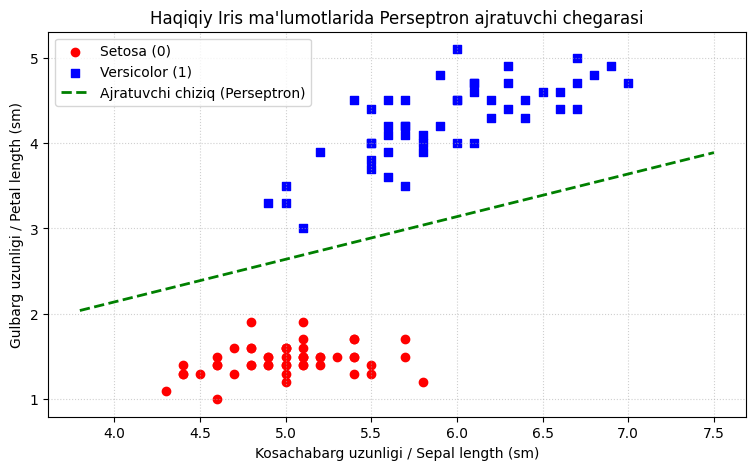

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# 1. Haqiqiy Iris datasetini yuklash
iris = load_iris()

# Faqat ikkita sinfni olamiz: 0 (Setosa) va 1 (Versicolor) -> jami 100 ta namuna
mask = (iris.target == 0) | (iris.target == 1)
# Oson tasavvur qilish uchun 2 ta belgini tanlaymiz:
# 0: Kosachabarg uzunligi (Sepal length), 2: Gulbarg uzunligi (Petal length)
X = iris.data[mask][:, [0, 2]]
y = iris.target[mask]

# Ma'lumotlarni aralashtirish (shuffling)
np.random.seed(42)
shuffle_idx = np.random.permutation(len(y))
X, y = X[shuffle_idx], y[shuffle_idx]

# 2. Giperparametrlar va boshlang'ich sozlamalar
learning_rate = 0.01
epochs = 10

weights = np.zeros(X.shape[1])  # [w1, w2] = [0.0, 0.0]
bias = 0.0
errors_per_epoch = []

print(f"Dataset hajmi: {X.shape[0]} ta namuna (haqiqiy o'lchamlar)")
print(f"Boshlang'ich vaznlar: w = {weights}, b = {bias}\n")
print("-" * 50)

# 3. Perseptron o'rganish sikli
for epoch in range(1, epochs + 1):
    epoch_errors = 0

    for xi, target in zip(X, y):
        # Og'irlikli yig'indi va bashorat
        z = np.dot(xi, weights) + bias
        prediction = 1 if z >= 0 else 0

        # Xatoni hisoblash
        error = target - prediction

        # Agar xato bo'lsa, parametrlarni yangilash qoidasi
        if error != 0:
            weights += learning_rate * error * xi
            bias += learning_rate * error
            epoch_errors += 1

    errors_per_epoch.append(epoch_errors)
    print(f"Epoxa {epoch:2d}: Jami xatoliklar soni = {epoch_errors} | "
          f"w = {np.round(weights, 4)}, b = {bias:.4f}")

    # Barcha namunalar to'g'ri tasniflansa, to'xtatamiz
    if epoch_errors == 0:
        print(f"\nModel {epoch}-epoxada to'liq konvergensiyaga erishdi (0 ta xato)!")
        break

# 4. Natijalarni grafikda tasvirlash
plt.figure(figsize=(9, 5))

# Ma'lumot nuqtalarini chizish
plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], color='red', marker='o', label='Setosa (0)')
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color='blue', marker='s', label='Versicolor (1)')

# Ajratuvchi to'g'ri chiziq tenglamasi: w1*x1 + w2*x2 + b = 0 => x2 = -(w1*x1 + b) / w2
x1_vals = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)
x2_vals = -(weights[0] * x1_vals + bias) / weights[1]
plt.plot(x1_vals, x2_vals, color='green', linestyle='--', linewidth=2, label="Ajratuvchi chiziq (Perseptron)")

plt.title("Haqiqiy Iris ma'lumotlarida Perseptron ajratuvchi chegarasi")
plt.xlabel("Kosachabarg uzunligi / Sepal length (sm)")
plt.ylabel("Gulbarg uzunligi / Petal length (sm)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

Bitta perseptron tekislikda faqat bitta to'g'ri chiziq torta oladi, XOR (istisno YOKI) esa qarama-qarshi diagonallarda yotgan nuqtalar sababli bitta chiziq bilan ajratib bo'lmaydigan — chiziqli ajralmas (linearly inseparable) masaladir.

Geometrik boshi berk ko'cha.
XOR jadvalidagi 4 ta nuqtani tekislikka qo'ysak:

Ikkita 1 bir-biriga diagonal, ikkita 0 esa ikkinchi diagonal bo'ylab joylashgan. Qog'ozga bitta to'g'ri chiziq chizib, doiralarni to'rtburchaklardan ajratishga urinib ko'ring — buning iloji yo'q.
Tarixiy zarba (1969-yil): Marvin Minskiy va Seymur Papert o'zlarining "Perceptrons" kitobida bitta neyron hatto oddiy XOR amalini ham bajara olmasligini matematik isbotlab berishdi. Bu sun'iy intellekt sohasiga investitsiyalarning to'xtashiga va birinchi "AI Qishi" (AI Winter) boshlanishiga sabab bo'ldi.

1-yo'l: Chiziqlarni ko'paytiramiz (Yashirin qatlam / Hidden Layer)

Bitta chiziq ikkiga bo'la olmasa, ikkita chiziq tortamiz va ularni birlashtiramiz. Buning uchun neyronlarni qatlam-qatlam qilib joylashtiramiz:

1-chiziq (NAND neyroni): Yuqorigi o'ng burchakdagi (1,1) nuqtani kesib tashlaydi.

2-chiziq (OR neyroni): Pastki chap burchakdagi (0,0) nuqtani kesib tashlaydi.

3-Qaror (AND neyroni): Ikkala chiziq oralig'ida qolgan nuqtalarni "1" deb e'lon qiladi.

Mana shu tuzilma Ko'p qatlamli perseptron (Multilayer Perceptron — MLP) deyiladi. Deep Learning'dagi "Deep" (chuqur) so'zi aynan mana shu o'rtadagi yashirin qatlamlar soni ortib borishi tufayli vujudga kelgan.

2-yo'l: Fazoni o'zgartiramiz (Feature Transformation)
Agar 2D tekislikda nuqtalar chiziq bilan ajralmasa, ularni 3-o'lchamga (3D) ko'tarish mumkin.

In [38]:
import numpy as np

# 1. Umumiy perceptron qadami
def perceptron(x, w, b):
    z = np.dot(x, w) + b
    return 1 if z >= 0 else 0

# 2. Yashirin qatlamdagi 1-neyron: NAND
def NAND_gate(x):
    return perceptron(x, w=np.array([-1.0, -1.0]), b=1.5)

# 3. Yashirin qatlamdagi 2-neyron: OR
def OR_gate(x):
    return perceptron(x, w=np.array([1.0, 1.0]), b=-0.5)

# 4. Chiqish qatlamidagi neyron: AND
def AND_gate(h):
    return perceptron(h, w=np.array([1.0, 1.0]), b=-1.5)

# 5. Ikki qatlamli XOR arxitekturasi
def XOR_network(x):
    # --- 1-qatlam: Yashirin qatlam (Hidden Layer) ---
    h1 = NAND_gate(x)  # (1, 1) holatini ajratib oladi
    h2 = OR_gate(x)    # (0, 0) holatini ajratib oladi
    hidden_output = np.array([h1, h2])

    # --- 2-qatlam: Chiqish qatlami (Output Layer) ---
    y = AND_gate(hidden_output)

    return y, h1, h2

# Sinov ma'lumotlari
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

# Natijalarni qadamma-qadam ko'rish
print(" Kirishlar  |   Yashirin qatlam   | Chiqish")
print(" x1    x2   | NAND(h1)   OR(h2)   |  XOR(y)")
print("-" * 43)

for x in X:
    y, h1, h2 = XOR_network(x)
    print(f"  {x[0]}     {x[1]}   |    {h1}         {h2}     |    {y}")

 Kirishlar  |   Yashirin qatlam   | Chiqish
 x1    x2   | NAND(h1)   OR(h2)   |  XOR(y)
-------------------------------------------
  0     0   |    1         0     |    0
  0     1   |    1         1     |    1
  1     0   |    1         1     |    1
  1     1   |    0         1     |    0


https://colab.research.google.com/drive/1tce6-nQdpYH_0warItJwv9aawtA2FzdF#scrollTo=bB-9DJWBF2nC$0

Vaznlar (w): Har bir neyron oldingi qatlamdagi barcha neyronlarga bog'langan va har bir bog'lanish o'z vazniga (ahamiyatiga) ega. Musbat vaznlar rag'batlantiradi, manfiy vaznlar esa bostiradi
Vaznli yig'indi: Oldingi qatlamdagi barcha faolliklar o'z vaznlariga ko'paytirilib jamlanadi

Siljish (b / Bias): Neyron faollashishi uchun vaznli yig'indi qanchalik yuqori bo'lishi kerakligini belgilovchi chegara qiymat [11:15].

Sigmoid funksiyasi (σ): Vaznli yig'indini istalgan haqiqiy sondan 0 va 1 oralig'iga siqib beruvchi silliq egri chiziqli faollashtirish funksiyasi

ReLU (Rectified Linear Unit) — neyron tarmoqlarda eng ko'p ishlatiladigan, qoidasi nihoyatda oddiy bo'lgan faollashtirish funksiyasi.

Uning butun mantiqi bittagina qoidaga asoslanadi: "Manfiy son kelsa — uni 0 ga aylantir, musbat son kelsa — o'z holicha qoldir."

Matematik formulasi:f(x)=max(0,x)

# Forward va Backpropagation

Forward pass (oldinga uzatish) — bu kirish ma'lumotlarining neyron tarmoq qatlamlari bo'ylab boshidan oxirigacha o'tib, yakuniy natija (bashorat) hosil qilish jarayoni.

Oddiy qilib aytganda: bu tarmoqning berilgan savolga javob hisoblash bosqichidir. Tarmoq hali bu bosqichda xatolarini to'g'rilamaydi, faqat mavjud vaznlari bilan hisob-kitob qilib, javobni (y^) chiqaradi.

Har qanday neyron Forward pass vaqtida ketma-ket ikkita oddiy amalni bajaradi:   

Chiziqli yig'indi (z): Kirish qiymatlari o'z vaznlariga ko'paytirilib, bias (siljish) bilan qo'shiladi.   

Faollashtirish (a): Chiqqan yig'indi no-chiziqli faollashtirish funksiyasidan o'tkaziladi. Faollashtirish funksiyasi: ReLU (f(z)=max(0,z)) yoki sigmoid.

In [39]:
import numpy as np
x  = np.array([1., 2.])
W1 = np.array([[1., 2.], [-1., 1.]])
b1 = np.zeros(2)
w2 = np.array([2., 1.])
b2 = 1.0

def forward(x):
    z1 = x @ W1 + b1
    h = np.maximum(0, z1)
    return z1, h, h @ w2 + b2

z1, h, y_hat = forward(x)
print(z1, h, y_hat)

[-1.  4.] [0. 4.] 5.0


Loss function (yo'qotish funksiyasi) — bu model chiqargan bashorat (y^) bilan obyektning haqiqiy qiymati (y) orasidagi farqni bitta sonli ko'rsatkichga aylantirib beruvchi mezon.

Oddiy qilib aytganda, u tarmoqning qanchalik "adashganini" baholaydigan jarima tizimidir: xato qancha katta bo'lsa, yo'qotish qiymati shuncha yuqori bo'ladi, bashorat haqiqatga yaqinlashgani sari esa nolga intiladi. Model o'qitish jarayonining (Backward pass) bosh maqsadi — aynan shu funksiya qiymatini minimallashtirishdir.

Loss function (bitta namuna uchun): Faqat bitta xi o'quv namunasi bo'yicha hisoblangan xatolik: L(y, y^).

In [40]:
import numpy as np

def mse(y, p):
    return np.mean((p - y) ** 2)

def bce(y, p):
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

print(mse(np.array([2.]), np.array([5.])))
for p in (0.9, 0.5, 0.1):
    print(p, round(bce(1, p), 4))

9.0
0.9 0.1054
0.5 0.6931
0.1 2.3026


Backward pass (teskari uzatish) va Backpropagation (xatolikni teskari tarqatish) — neyron tarmoqning yo'qotish funksiyasi (L) qiymatini kamaytirish maqsadida barcha vaznlar (w) va siljishlar (b) bo'yicha xususiy hosilalarni (gradientlarni) oxirgi qatlamdan birinchi qatlam sari hisoblab chiqish jarayonidir.

Bu jarayon matematik jihatdan to'liq zanjir qoidasiga (Chain rule) tayanadi.

Backward Pass va Backpropagation (Teskari tarqalish)

**Backward pass** va **Backpropagation** — neyron tarmoqning yo'qotish funksiyasi ($L$) qiymatini minimallashtirish uchun barcha vaznlar ($w$) va siljishlar ($b$) bo'yicha xususiy hosilalarni (gradientlarni) chiqish qatlamidan kirish qatlami sari zanjir qoidasi orqali hisoblash jarayonidir.

---

1. Zanjir qoidasi (*Chain rule*) nima?

Agar murakkab funksiya bir nechta oraliq o'zgaruvchilardan tashkil topgan bo'lsa ($y = f(u)$ va $u = g(x)$), uning hosilasi oraliq hosilalar ko'paytmasiga teng bo'ladi:

$$\frac{dy}{dx} = \frac{dy}{du} \cdot \frac{du}{dx}$$

Neyron tarmog'idagi bitta neyron bo'ylab ma'lumotlar oqimi:
1. **Kirish signali:** $x$
2. **Chiziqli yig'indi:** $z = w \cdot x + b$
3. **Faollashtirilgan chiqish:** $a = f(z)$
4. **Yo'qotish (xatolik):** $L(y, a)$

Bizning maqsadimiz — $w$ va $b$ o'zgarsa, umumiy xatolik ($L$) qanchalik o'zgarishini aniqlash:

$$\frac{\partial L}{\partial w} = \frac{\partial L}{\partial a} \cdot \frac{\partial a}{\partial z} \cdot \frac{\partial z}{\partial w}$$

$$\frac{\partial L}{\partial b} = \frac{\partial L}{\partial a} \cdot \frac{\partial a}{\partial z} \cdot \frac{\partial z}{\partial b}$$

---

 2. Zanjir bo'g'inlarining alohida hosilalari

* **1-bo'g'in: $\frac{\partial L}{\partial a}$** — Xatolikning neyron chiqishiga nisbatan sezgirligi.  
  Kvadratik yo'qotish funksiyasi ($L = \frac{1}{2}(y - a)^2$) uchun:
  $$\frac{\partial L}{\partial a} = -(y - a) = a - y$$

* **2-bo'g'in: $\frac{\partial a}{\partial z}$** — Faollashtirish funksiyasining hosilasi ($f'(z)$).  
  **Sigmoid** $\sigma(z) = \frac{1}{1 + e^{-z}}$ funksiyasining hosilasi:
  $$\frac{\partial a}{\partial z} = a(1 - a)$$

* **Oraliq xatolik signali ($\delta$):**  
  Dastlabki ikki bo'g'inning ko'paytmasi oraliq xatolik gradienti ($\delta$) deb ataladi:
  $$\delta = \frac{\partial L}{\partial z} = \frac{\partial L}{\partial a} \cdot \frac{\partial a}{\partial z} = (a - y) \cdot a(1 - a)$$

* **3-bo'g'in: $\frac{\partial z}{\partial w}$ va $\frac{\partial z}{\partial b}$** — Chiziqli yig'indining parametrlar bo'yicha hosilasi:
  $$z = w \cdot x + b \implies \frac{\partial z}{\partial w} = x \quad \text{va} \quad \frac{\partial z}{\partial b} = 1$$

 Yakuniy gradient formulalari:
$$\frac{\partial L}{\partial w} = \delta \cdot x$$
$$\frac{\partial L}{\partial b} = \delta \cdot 1$$

---

3. Raqamli misol (End-to-end hisoblash)

 Boshlang'ich parametrlar:
* Kirish: $x = 2.0$
* Haqiqiy nishon: $y = 1.0$
* Joriy parametrlar: $w = 0.5, \quad b = 0.0$
* O'rganish tezligi: $\eta = 0.1$
* Yo'qotish funksiyasi: $L = \frac{1}{2}(y - a)^2$
* Faollashtirish funksiyasi: Sigmoid ($\sigma$)

---

1-bosqich: Forward Pass (Oldinga uzatish)
1. **Chiziqli yig'indi:**  
   $$z = w \cdot x + b = (0.5 \cdot 2.0) + 0.0 = 1.0$$
2. **Faollashtirish:**  
   $$a = \sigma(1.0) = \frac{1}{1 + e^{-1.0}} \approx 0.731$$
3. **Yo'qotish (xatolik) qiymati:**  
   $$L = \frac{1}{2}(1.0 - 0.731)^2 = \frac{1}{2}(0.269)^2 \approx 0.0362$$

---

2-bosqich: Backward Pass (Teskari hisoblash)
1. $\frac{\partial L}{\partial a} = a - y = 0.731 - 1.0 = -0.269$
2. $\frac{\partial a}{\partial z} = a(1 - a) = 0.731 \cdot (1 - 0.731) \approx 0.1966$
3. $\delta = \frac{\partial L}{\partial z} = -0.269 \cdot 0.1966 \approx -0.0529$
4. **Parametrlar bo'yicha gradientlar:**  
   $$\frac{\partial L}{\partial w} = \delta \cdot x = -0.0529 \cdot 2.0 = -0.1058$$  
   $$\frac{\partial L}{\partial b} = \delta \cdot 1 = -0.0529$$

---

3-bosqich: Gradient tushishi (Vaznlarni yangilash)

Parametrlarni xatolik kamayishi yo'nalishi bo'yicha yangilaymiz:

$$w_{yangi} = w_{eski} - \eta \cdot \frac{\partial L}{\partial w} = 0.5 - 0.1 \cdot (-0.1058) = 0.5 + 0.01058 = \mathbf{0.51058}$$

$$b_{yangi} = b_{eski} - \eta \cdot \frac{\partial L}{\partial b} = 0.0 - 0.1 \cdot (-0.0529) = 0.0 + 0.00529 = \mathbf{0.00529}$$

> **Xulosa:** Model bashorati ($0.731$) kutilgan natijadan ($1.0$) kichik bo'lgani sababli, hisoblangan manfiy gradient parametrlarni oshirishga xizmat qildi. Keyingi qadamda yig'indi kattalashib, natija $1.0$ ga yaqinlashadi.

In [41]:
y = 2.0

def backward(x, y):
    z1, h, y_hat = forward(x)
    d = 2 * (y_hat - y)
    dw2 = h * d
    dh = w2 * d
    dz1 = dh * (z1 > 0)
    dW1 = np.outer(x, dz1)
    return dW1, dz1, dw2, d

dW1, db1, dw2, db2 = backward(x, y)
print(dW1)
print(db1)
print(dw2, db2)

[[ 0.  6.]
 [ 0. 12.]]
[0. 6.]
[ 0. 24.] 6.0


In [42]:
import numpy as np

sigmoid = lambda z: 1 / (1 + np.exp(-z)) #Har qanday haqiqiy sonni (0,1) oralig'iga siqib beruvchi Sigmoid faollashtirish funksiyasi.

class MLP:
    def __init__(self, n_in, n_h, seed=0):
        r = np.random.default_rng(seed)
        self.W1 = r.normal(0, 1, (n_in, n_h))
        self.W2 = r.normal(0, 1, (n_h, 1))
        self.b1, self.b2 = np.zeros(n_h), np.zeros(1)

    def forward(self, X):
        self.h = sigmoid(X @ self.W1 + self.b1)
        self.p = sigmoid(self.h @ self.W2 + self.b2)
        return self.p

    def step(self, X, y, lr):
        # 1. Chiqish qatlami gradienti
        dz2 = (self.p - y) / len(X)

        # 2. Yashirin qatlam gradienti (Zanjir qoidasi)
        dz1 = dz2 @ self.W2.T * self.h * (1 - self.h)

        # 3. Parametrlarni yangilash (Gradient Descent)
        self.W2 -= lr * (self.h.T @ dz2)
        self.b2 -= lr * dz2.sum(0)
        self.W1 -= lr * (X.T @ dz1)
        self.b1 -= lr * dz1.sum(0)

In [43]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

net = MLP(2, 4, seed=1)
for ep in range(5001):
    p = net.forward(X)
    loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    if ep in (0, 500, 1000, 5000):
        print(ep, round(loss, 4))
    net.step(X, y, lr=1.0)

print((net.forward(X) > 0.5).astype(int).ravel())

0 0.7452
500 0.0714
1000 0.014
5000 0.0016
[0 1 1 0]


PyTorch Autograd — bu PyTorch-ning avtomatik differensiallash dvigateli (automatic differentiation engine).

qo'lda hisoblagan murakkab hosilalaringizni (Zanjir qoidasi — Chain Rule, dz1, dz2, matritsa transponirlashlarini) Autograd kompyuter xotirasida o'zi avtomatik kuzatib boradi va bittagina loss.backward() buyrug'i orqali barcha hosilalarni (gradientlarni) bir zumda hisoblab beradi.

Forward pass (Oldinga hisoblash): Siz tenzorlar ustida amallar bajarganingizda (ko'paytirish, qo'shish, ReLU va h.k.), PyTorch natijani hisoblash bilan birga qaysi operatsiya qaysi tenzordan hosil bo'lganini daraxtsimon grafik (DAG — Directed Acyclic Graph) ko'rinishida yozib boradi.

Backward pass (Teskari hisoblash): Siz y.backward() deb buyruq berganingizda, Autograd ushbu grafik bo'ylab orqaga qarab harakatlanadi va Zanjir qoidasini qo'llab, har bir boshlang'ich parametr bo'yicha hosilani topadi.

Autogradning 4 ta asosiy tayanchi

Autograd bilan ishlashda bilish shart bo'lgan 4 ta atribut mavjud:

requires_grad=True: PyTorch-ga bu tenzor ustidagi har bir amalni grafikda eslab qolishni buyuradi. Neyron tarmoqning o'rganuvchi vaznlari (W,b) aynan shunday belgilanadi.

grad_fn: Tenzorni qaysi matematik amal hosil qilganini ko'rsatuvchi ko'rsatkich (masalan, <AddBackward0>, <MulBackward0>). Forward passda avtomatik biriktiriladi.

.backward(): Teskari tarqalishni (Backpropagation) ishga tushiruvchi funksiya.

.grad: .backward() chaqirilgandan so'ng hisoblangan yakuniy hosilalar () saqlanadigan joy.

In [44]:
import torch

# 1. requires_grad=True bilan tenzor yaratamiz
x = torch.tensor(2.0, requires_grad=True)

# 2. Forward pass: operatsiyalar bajaramiz
y = 3 * (x ** 2) + 5 * x + 2

# y ning qiymati: 3*(4) + 10 + 2 = 24
# y.grad_fn ga qarasak, u grafikni eslab qolganini ko'ramiz
print("y ning qiymati:", y.item())
print("y ning grad_fn:", y.grad_fn)

# 3. Backward pass: hosilani avtomatik hisoblash
y.backward()

# 4. Hosilani x.grad orqali ko'ramiz
print("x bo'yicha hosila (dy/dx):", x.grad.item())  # Natija: 17.0

y ning qiymati: 24.0
y ning grad_fn: <AddBackward0 object at 0x7c0e1b5be590>
x bo'yicha hosila (dy/dx): 17.0


A. Gradientlar to'planishi (Accumulation) va ularni tozalash
PyTorch-da .backward() har safar chaqirilganda, yangi hisoblangan gradientlar .grad dagi eski qiymat ustiga qo'shilib (yig'ilib) boraveradi.
Shuning uchun har bir yangi o'quv qadamidan oldin gradientlarni tozalash shart:

B. Kuzatuvni o'chirish (torch.no_grad() va .detach())
Tarmoqni sinash (test/inference) jarayonida yoki vaznlarni yangilash paytida bizga gradientlar kerak bo'lmaydi. Xotira va hisoblash quvvatini tejash uchun Autograd kuzatuvini o'chirib qo'yamiz:

In [48]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Havfsiz ishga tushirish uchun sodda model va o'zgaruvchilarni yaratamiz
model = nn.Linear(2, 1)
optimizer = optim.SGD(model.parameters(), lr=0.1)
x = torch.tensor([1.0, 2.0], requires_grad=True)
y = model(x)
y.backward()

# Optimizer ishlatilganda:
optimizer.zero_grad()

# Yoki tenzorni qo'lda tozalaganda:
if x.grad is not None:
    x.grad.zero_()

# 1-usul: Blok ichida o'chirish (Inference vaqtida)
X_test = torch.randn(5, 2)
with torch.no_grad():
    predictions = model(X_test)  # Hech qanday hisoblash grafigi qurilmaydi

# 2-usul: Tenzorni grafikdan uzib olish
x_detached = y.detach()

In [49]:
import torch

# Ma'lumotlar va tasodifiy vaznlar
X = torch.randn(4, 2)
y = torch.tensor([[0.0], [1.0], [1.0], [0.0]])

# requires_grad=True — vaznlar bo'yicha hosila olinishini bildiradi
W1 = torch.randn(2, 4, requires_grad=True)
b1 = torch.zeros(4, requires_grad=True)
W2 = torch.randn(4, 1, requires_grad=True)
b2 = torch.zeros(1, requires_grad=True)

learning_rate = 0.1

# Bitta o'qitish qadami:
# 1. Forward pass
h = torch.sigmoid(X @ W1 + b1)
p = torch.sigmoid(h @ W2 + b2)

# 2. Loss hisoblash (MSE misolida)
loss = torch.mean((p - y) ** 2)

# 3. Backward pass (BUTUN BACKPROPAGATION SHU YERDA SODIR BO'LADI)
loss.backward()

# 4. Parametrlarni yangilash (Gradient descent)
with torch.no_grad():
    W1 -= learning_rate * W1.grad
    b1 -= learning_rate * b1.grad
    W2 -= learning_rate * W2.grad
    b2 -= learning_rate * b2.grad

    # 5. Gradientlarni keyingi qadam uchun tozalash
    W1.grad.zero_()
    b1.grad.zero_()
    W2.grad.zero_()
    b2.grad.zero_()

In [50]:
import torch

x  = torch.tensor([1., 2.])
W1 = torch.tensor([[1., 2.], [-1., 1.]], requires_grad=True)
b1 = torch.zeros(2, requires_grad=True)
w2 = torch.tensor([2., 1.], requires_grad=True)
b2 = torch.tensor(1., requires_grad=True)

y_hat = torch.relu(x @ W1 + b1) @ w2 + b2
loss = (y_hat - 2) ** 2
loss.backward()

print(W1.grad.numpy())
print(b1.grad.numpy())
print(w2.grad.numpy(), b2.grad.item())

[[ 0.  6.]
 [ 0. 12.]]
[0. 6.]
[ 0. 24.] 6.0


torch.nn.Module — arxitekturani (qatlamlar va forward pass) ixcham guruhlash va barcha vaznlarni boshqarish uchun.

torch.optim — gradientlar asosida vaznlarni yangilash (SGD, Adam, AdamW kabi algoritmlar) uchun.

Professional model arxitekturasi (torch.nn.Module)
Har qanday model nn.Module klassidan meros oladi va kamida ikkita asosiy metoddan iborat bo'ladi:

__init__: super().__init__() orqali asosiy klass initsializatsiya qilinadi va kerakli qatlamlar (nn.Linear, nn.Conv2d, nn.Dropout va h.k.) aniqlanadi.

forward: Kirish ma'lumotlari (x) qatlamlardan ketma-ket qanday o'tishini ifodalaydi.

In [51]:
import torch
import torch.nn as nn

class ProfessionalMLP(nn.Module):
    def __init__(self, in_features: int, hidden_features: int, out_features: int):
        super().__init__()

        # Qatlamlarni ketma-ket yig'ish (nn.Sequential orqali ixchamlashtirish mumkin)
        self.network = nn.Sequential(
            nn.Linear(in_features, hidden_features),
            nn.ReLU(),
            nn.Dropout(p=0.2),  # Overfitting'ning oldini olish uchun
            nn.Linear(hidden_features, hidden_features),
            nn.ReLU(),
            nn.Linear(hidden_features, out_features)
            # Klassifikatsiyada CrossEntropyLoss ishlatsak, oxiriga Softmax qo'yilmaydi!
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)

O'qitish tsiklining 5 ta oltin qadami (Training Loop)

optimizer.zero_grad() — eski batchdan qolgan gradientlarni tozalash.

outputs = model(inputs) — Forward pass (bashorat olish).

loss = criterion(outputs, targets) — Xatolikni hisoblash.

loss.backward() — Backward pass (gradientlarni avtomatik hisoblash).

optimizer.step() — Vaznlarni yangilash (gradient tushishi bo'yicha siljish).

In [52]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# 1. Qurilmani aniqlash (GPU bo'lsa CUDA, aks holda CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Ishlatilayotgan qurilma: {device}")

# 2. Model, Loss va Optimizer-ni sozlash
in_dim, hidden_dim, out_dim = 10, 32, 2
model = ProfessionalMLP(in_features=in_dim, hidden_features=hidden_dim, out_features=out_dim)
model.to(device)  # Modelni to'g'ri qurilmaga yuklash

criterion = nn.CrossEntropyLoss()
# AdamW — vaznlarni regulyarizatsiya qilishda zamonaviy standart
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

# (Misol uchun sun'iy ma'lumotlar va DataLoader)
X_dummy = torch.randn(200, in_dim)
y_dummy = torch.randint(0, out_dim, (200,))
dataset = TensorDataset(X_dummy, y_dummy)
train_loader = DataLoader(dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(dataset, batch_size=32, shuffle=False)

# 3. O'qitish funksiyasi
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()  # Modelni o'qitish rejimiga o'tkazish (Dropout va BatchNorm ishlaydi)
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in dataloader:
        inputs, targets = inputs.to(device), targets.to(device)

        # 5 ta oltin qadam:
        optimizer.zero_grad()              # 1. Gradientlarni tozalash
        outputs = model(inputs)            # 2. Forward pass
        loss = criterion(outputs, targets) # 3. Xatolikni hisoblash
        loss.backward()                    # 4. Backward pass (Backpropagation)
        optimizer.step()                   # 5. Vaznlarni yangilash

        # Statistika
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

# 4. Baholash funksiyasi (Validation)
def evaluate(model, dataloader, criterion, device):
    model.eval()  # Baholash rejimiga o'tkazish (Dropout o'chadi)
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():  # Autograd grafik qurmaydi — xotira va tezlik tejaladi
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

    return running_loss / total, correct / total

# 5. Butun jarayonni ishga tushirish (Epochs)
EPOCHS = 5
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    print(f"Epoch [{epoch}/{EPOCHS}] | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f}, Acc: {val_acc*100:.2f}%")

Ishlatilayotgan qurilma: cpu
Epoch [1/5] | Train Loss: 0.6954, Acc: 52.00% | Val Loss: 0.6925, Acc: 52.00%
Epoch [2/5] | Train Loss: 0.6990, Acc: 49.50% | Val Loss: 0.6882, Acc: 49.50%
Epoch [3/5] | Train Loss: 0.6906, Acc: 50.00% | Val Loss: 0.6858, Acc: 53.00%
Epoch [4/5] | Train Loss: 0.6858, Acc: 54.00% | Val Loss: 0.6839, Acc: 57.00%
Epoch [5/5] | Train Loss: 0.6823, Acc: 57.50% | Val Loss: 0.6820, Acc: 55.00%


model(x) vs model.forward(x):

Hech qachon model.forward(x) deb to'g'ridan-to'g'ri chaqirmang. Har doim model(x) ko'rinishida chaqiring. Chunki model(x) PyTorch-ning ichki boshqaruvchi funksiyalari va maxsus hooklarini to'g'ri ishga tushiradi.
model.train() va model.eval() farqi:

Bu rejimlar ayniqsa nn.Dropout (o'qitishda neyronlarni o'chiradi, baholashda yoqadi) va nn.BatchNorm (baholashda harakatlanuvchi o'rtacha qiymatdan foydalanadi) qatlamlari to'g'ri ishlashi uchun shart.
with torch.no_grad()::

Modelni sinash yoki ishlab chiqarishda (inference) ishlatganda ushbu blok ichida chaqirish shart. Bu hisoblash grafigi qurilishini to'xtatadi va video xotirani (VRAM) sezilarli darajada tejaydi.
Logits va Loss mosligi:

Ko'p sinfli klassifikatsiyada nn.CrossEntropyLoss() o'z ichida ichki LogSoftmax va NLLLossni birlashtirgan. Shuning uchun modelning eng oxirgi qatlamiga qo'shimcha Softmax qo'yilmaydi (chunki bu raqamli beqarorlikka — numerical instabilityga olib keladi).

https://docs.google.com/document/d/1_ZeVbOHyKSrpzZLJsNPMsEG6My7X_uMj/edit$0

# Aktivatsiya funksiyalari va Loss

Aktivatsiya funksiyasi — neyronning kiruvchi signallar yigʻindisini (z=Wx+b) qabul qilib, uni qanday kuch bilan keyingi qatlamga uzatishni (yoki uzatmaslikni) hal qiluvchi matematik funksiyadir.

Agar aktivatsiya funksiyasi boʻlmasa, tarmoqqa 100 ta qatlam qoʻshsangiz ham, ularning barchasi bitta oddiy chiziqli formulaga aylanib qoladi. Aktivatsiya funksiyasi tarmoqqa nochiziqlik olib kiradi va unga egri chiziqlar, rasmlar, matnlar kabi murakkab tuzilmalarni oʻrganish imkonini beradi.

### Asosiy aktivatsiya funksiyalari

Aktivatsiya funksiyasi — neyronning kiruvchi chiziqli yigʻindisini ($z = Wx + b$) qabul qilib, uni qanday kuch bilan keyingi qatlamga uzatishni hal qiluvchi nochiziqli funksiyadir. U neyron tarmoqqa nochiziqlik (non-linearity) olib kiradi va murakkab qonuniyatlarni oʻrganish imkonini beradi.

---

#### 1. Sigmoid
* **Formulasi:**
  $$\sigma(z) = \frac{1}{1 + e^{-z}}$$
* **Chiqish oraligʻi:** $(0, 1)$
* **Qoʻllanishi:** Ikkilik klassifikatsiyaning (binary classification) chiqish qatlamida natijani ehtimollik sifatida ifodalash uchun ishlatiladi.
* **Kamchiligi:** $z$ qiymati juda katta musbat yoki manfiy boʻlganda hosilasi nolga yaqinlashadi, bu esa chuqur tarmoqlarda **gradientning soʻnishi (vanishing gradient)** muammosiga sabab boʻladi[cite: 1].

#### 2. Tanh (Giperbolik tangens)
* **Formulasi:**
  $$\tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$$
* **Chiqish oraligʻi:** $(-1, 1)$
* **Afzalligi:** Markazi nolga teng (zero-centered), bu esa parametrlarning optimallashuvini nisbatan tezlashtiradi.
* **Kamchiligi:** Sigmoid kabi toʻyinish sohalarida gradient soʻnishi kuzatiladi.

#### 3. ReLU (Rectified Linear Unit)
* **Formulasi:**
  $$f(z) = \max(0, z)$$
* **Chiqish oraligʻi:** $[0, \infty)$
* **Afzalligi:** Hisoblash jihatidan juda yengil. Musbat sohada ($z > 0$) gradient doimiy 1 ga teng boʻlib, soʻnmaydi.
* **Kamchiligi:** *Dying ReLU* muammosi — agar neyron kirishi doimiy manfiy ($z < 0$) boʻlib qolsa, gradient 0 ga aylanadi va neyron oʻrganishdan toʻxtaydi.

#### 4. Leaky ReLU
* **Formulasi:**
  $$f(z) = \max(\alpha z, z) \quad (\text{odatda } \alpha = 0.01)$$
* **Chiqish oraligʻi:** $(-\infty, \infty)$
* **Afzalligi:** Manfiy sohada nol oʻrniga kichik qiyalik qoldirilishi orqali neyronlarning "oʻlib" qolishining oldi olinadi.

#### 5. Softmax
* **Formulasi:**
  $$\text{Softmax}(z_i) = \frac{e^{z_i}}{\sum_{j} e^{z_j}}$$
* **Chiqish oraligʻi:** $(0, 1)$, barcha chiqishlar yigʻindisi aniq 1 ga teng: $\sum \hat{y}_i = 1$.
* **Qoʻllanishi:** Koʻp sinfli klassifikatsiya (multi-class classification) masalalarida eng oxirgi chiqish qatlamida ehtimolliklar taqsimotini shakllantirish uchun ishlatiladi.

#### 6. GELU va SiLU (Swish)
* **Mohiyati:** ReLU ning silliqlashtirilgan va ehtimollik tabiatiga asoslangan zamonaviy shakllari.
* **Qoʻllanishi:** Hozirgi zamonaviy Transformer modellari (BERT, GPT, LLaMA) da asosiy aktivatsiya funksiyasi sifatida qoʻllaniladi.

---

Qisqacha taqqoslash jadvali

| Funksiya | Chiqish oraligʻi | Tavsiya etiladigan oʻrni | Asosiy xususiyati / Cheklovi |
| :--- | :---: | :--- | :--- |
| **Sigmoid**[cite: 1] | $(0, 1)$ | Chiqish qatlami (ikkilik klassifikatsiya) | Gradient soʻnishi bor[cite: 1] |
| **Tanh** | $(-1, 1)$ | Yashirin qatlamlar (RNN, vaqt qatorlari) | Nolga markazlashgan |
| **ReLU** | $[0, \infty)$ | Yashirin qatlamlar (boshlangʻich standart) | Tez hisoblanadi, Dying ReLU xavfi bor |
| **Leaky ReLU** | $(-\infty, \infty)$ | Yashirin qatlamlar (ReLU oʻrniga) | Neyronlarning oʻlishiga yoʻl qoʻymaydi |
| **Softmax** | $(0, 1)$, $\sum=1$ | Chiqish qatlami (koʻp sinfli klassifikatsiya) | Ehtimolliklar taqsimotini beradi |


Yashirin qatlamlar uchun: Dastlab ReLU dan boshlang. Agar tarmoq oʻrganmay qotsa, Leaky ReLU yoki GELU ni sinab koʻring.

Ikkilik klassifikatsiya chiqishi uchun: Sigmoid.

Koʻp sinfli klassifikatsiya chiqishi uchun: Softmax.

Regressiya (aniq son bashorat qilish) chiqishi uchun: Aktivatsiya funksiyasi umuman qoʻyilmaydi (chiziqli qoldiriladi).

In [53]:
import numpy as np
z = np.array([-4., -2., 0., 2., 4.])
sig = 1 / (1 + np.exp(-z))
print(sig.round(4))
print((sig * (1 - sig)).round(4))
print(np.tanh(z).round(4))

[0.018  0.1192 0.5    0.8808 0.982 ]
[0.0177 0.105  0.25   0.105  0.0177]
[-0.9993 -0.964   0.      0.964   0.9993]


In [54]:
import numpy as np
z = np.array([-4., -2., 2., 4.])
print(np.maximum(0, z))
print(np.where(z > 0, z, 0.01 * z))
print(np.where(z > 0, 1.0, 0.01))


import torch
import torch.nn.functional as F
for f in (F.relu, F.leaky_relu):
    w = torch.tensor(1.0, requires_grad=True)
    h = f(w * 2 - 5)
    ((h - 1) ** 2).backward()
    print(round(h.item(), 4), round(w.grad.item(), 4))

[0. 0. 2. 4.]
[-0.04 -0.02  2.    4.  ]
[0.01 0.01 1.   1.  ]
0.0 0.0
-0.03 -0.0412


### Regressiya Loss funksiyalari: MSE va MAE

Regressiya masalalarida tarmoq aniq bir sonli qiymatni bashorat qiladi. Bashorat qilingan qiymat ($\hat{y}$) bilan haqiqiy qiymat ($y$) orasidagi tafovutni bitta son bilan oʻlchash uchun odatda **MSE** va **MAE** funksiyalaridan foydalaniladi.

---

#### 1. MSE (Mean Squared Error — Oʻrtacha kvadratik xatolik)

MSE barcha xatoliklarning kvadratlari yigʻindisining oʻrtachasini oladi[cite: 1].

* **Formulasi:**
  $$\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (y_i - \hat{y}_i)^2$$
  *(Nazariy hisob-kitoblarda hosilani soddalashtirish uchun koʻpincha $\frac{1}{2}(y - \hat{y})^2$ koʻrinishida olinadi[cite: 1]).*

* **Hosilasi ($\hat{y}$ boʻyicha):**
  $$\frac{\partial \text{MSE}}{\partial \hat{y}} = -2(y - \hat{y}) \quad \text{yoki} \quad (\hat{y} - y)$$[cite: 1]

* **Xususiyatlari:**
  * **Katta xatoliklarga sezgir:** Kvadratga koʻtarilgani sababli, kichik xatolarga nisbatan katta xatolarni ancha qattiqroq «jazolaydi».
  * **Silliq optimallashuv:** Funksiya hamma joyda silliq va differensiallanuvchi, xato kichraygan sari uning hosilasi (gradienti) ham kamayib, minimum nuqtaga ohista yetib boradi.
  * **Kamchiligi:** Anomaliya (outlier) qiymatlarga haddan tashqari taʼsirchan.

---

#### 2. MAE (Mean Absolute Error — Oʻrtacha mutlaq xatolik)

MAE bashorat va haqiqiy qiymat orasidagi modul (mutlaq qiymat) ayirmasining oʻrtachasini oladi.

* **Formulasi:**
  $$\text{MAE} = \frac{1}{N} \sum_{i=1}^{N} |y_i - \hat{y}_i|$$

* **Hosilasi ($\hat{y}$ boʻyicha):**
  $$\frac{\partial \text{MAE}}{\partial \hat{y}} = \text{sign}(\hat{y} - y) = \begin{cases} +1, & \hat{y} > y \\ -1, & \hat{y} < y \end{cases}$$
  *(Nol nuqtasida ($\hat{y} = y$) hosilasi aniqlanmagan).*

* **Xususiyatlari:**
  * **Anomaliyalarga chidamli (Robust):** Modul olingani sababli, alohida haddan tashqari chetga chiqqan sonlar modelni butunlay buzib yubormaydi.
  * **Kamchiligi:** Minimum nuqtaga yaqinlashganda ham hosila oʻzgarmaydi ($\pm 1$). Bu esa minimum atrofida sakrab qolishiga olib kelishi mumkin.

---

### MSE va MAE taqqoslanishi

| Xususiyat | MSE (L2 Loss) | MAE (L1 Loss) |
| :--- | :--- | :--- |
| **Matematik formula** | $\frac{1}{N}\sum (y - \hat{y})^2$[cite: 1] | $\frac{1}{N}\sum \|y - \hat{y}\|$ |
| **Anomaliyalarga munosabat** | Juda sezgir (kvadrat hisobiga) | Chidamli (chiziqli munosabat) |
| **Gradient xulqi** | Minimumga yaqinlashganda kichrayadi | Doimiy ($\pm 1$), minimumda sakraydi |
| **Differensiallanish** | Har bir nuqtada silliq hosilaga ega | $y = \hat{y}$ nuqtasida hosilasi yoʻq |
| **Qachon tanlanadi?** | Katta xatolar xavfli boʻlganda | Maʼlumotlarda shovqin koʻp boʻlganda |

In [55]:
import numpy as np
x = np.arange(1., 6.)
y = np.array([2., 4., 6., 8., 40.])
for a, b in ((2, 0), (8, -12)):
    p = a * x + b
    print(a, b, np.mean((y - p) ** 2), np.mean(np.abs(y - p)))

2 0 180.0 6.0
8 -12 72.0 7.2


### Klassifikatsiya Loss funksiyalari: BCE, CCE va Softmax

Klassifikatsiya masalalarida neyron tarmoq uzluksiz sonni emas, balki obyektning maʼlum bir sinfga tegishli boʻlish **ehtimolligini** ($\hat{y} \in [0, 1]$) bashorat qiladi.

Bu yerda MSE kabi kvadratik xatolar samarasiz boʻladi, chunki model adashganda juda sekin oʻrganadi. Shu sababli klassifikatsiyada axborot nazariyasiga asoslangan **Cross-Entropy (kesishgan entropiya)** loss funksiyalari ishlatiladi.

---

#### 1. Binary Cross-Entropy (BCE / Log Loss)

Faqat **2 ta sinf** mavjud boʻlgan holatlarda (masalan: spaml / spam emas, mushuk / it) qoʻllaniladi.

* **Chiqish qatlami:** Bitta neyron va **Sigmoid** aktivatsiyasi ($\hat{y} \in (0, 1)$).
* **Haqiqiy nishon:** $y \in \{0, 1\}$

* **Formulasi:**
  $$\text{BCE} = -\frac{1}{N} \sum_{i=1}^{N} \Big[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \Big]$$

* **Mantiqiy asosi:**
  * Agar $y = 1$ boʻlsa: Loss $= -\log(\hat{y})$. Model $\hat{y} = 1$ deb toʻgʻri topsa, $-\log(1) = 0$ (xato yoʻq). Agar $\hat{y} \to 0$ deb qattiq adashsa, $-\log(0) \to +\infty$ (cheksiz katta jazo).
  * Agar $y = 0$ boʻlsa: Loss $= -\log(1 - \hat{y})$. Model $\hat{y} = 0$ deb topsa, xato 0 ga teng boʻladi.

* **Sigmoid bilan birgalikdagi gradienti:**
  $$\frac{\partial \text{BCE}}{\partial z} = \hat{y} - y$$
  *(Ajablanarli darajada sodda va barqaror gradient hosil boʻladi).*

---

#### 2. Categorical Cross-Entropy (CCE)

Sinflar soni **3 yoki undan ortiq** ($C > 2$) boʻlganda (masalan: raqamlarni aniqlash 0–9, 100 xil hayvon turi) qoʻllaniladi.

* **Chiqish qatlami:** $C$ ta neyron va **Softmax** aktivatsiyasi ($\sum_{j=1}^C \hat{y}_j = 1$).
* **Haqiqiy nishon:** One-hot encoding formatida (masalan, $y = [0, 0, 1, 0]$).

* **Formulasi:**
  $$\text{CCE} = -\frac{1}{N} \sum_{i=1}^{N} \sum_{c=1}^{C} y_{i, c} \log(\hat{y}_{i, c})$$
  One-hot vektorida faqat bitta toʻgʻri sinf $1$ boʻlib, qolganlari $0$ boʻlgani sababli, bu formula aslida faqat toʻgʻri sinf ehtimolligiga tayanadi:
  $$\text{Loss} = -\log(\hat{y}_{to'g'ri})$$

---

#### 3. Softmax va Cross-Entropy nima uchun ajralmas juftlik?

Softmax funksiyasi oʻz-oʻzidan loss emas — u shunchaki chiziqli sonlarni ($z$) ehtimollikka ($0$ dan $1$ gacha) aylantirib beruvchi **aktivatsiya** hisoblanadi:
$$\hat{y}_i = \frac{e^{z_i}}{\sum_{j=1}^C e^{z_j}}$$

Cross-Entropy esa shu hosil boʻlgan ehtimolliklar taqsimoti bilan haqiqiy taqsimotni taqqoslaydigan **xatolik oʻlchovi**dir.

**Nima uchun ular birga ishlatiladi?**
1. **Gradientning oʻta soddaligi:**
   Softmax va Cross-Entropy zanjir qoidasi (Chain Rule) orqali birlashtirilganda murakkab hosilalar qisqarib ketadi va chiziqli kirish $z$ boʻyicha gradient quyidagicha qoladi:
   $$\frac{\partial \text{Loss}}{\partial z_i} = \hat{y}_i - y_i$$
   Yaʼni: *Bashorat ehtimolligi $-$ Haqiqiy nishon*. Bu hisoblashni juda tez va aniq qiladi.
2. **Raqamli barqarorlik (Numerical Stability):**
   Amaliyotda (PyTorch, TensorFlow) Softmax va Cross-Entropy alohida hisoblanmaydi (`LogSoftmax + NLLLoss` koʻrinishida bitta qilinadi). Bu $e^z$ ning haddan tashqari kattalashib ketishi (overflow) yoki $\log(0)$ (NaN) muammolarining oldini oladi.

---

### Klassifikatsiya Loss funksiyalari taqqoslanishi

| Xususiyat | Binary Cross-Entropy (BCE) | Categorical Cross-Entropy (CCE) |
| :--- | :--- | :--- |
| **Sinflar soni** | 2 ta sinf (Ikkilik) | 3 va undan koʻp sinflar (Koʻp sinfli) |
| **Aktivatsiya** | Sigmoid | Softmax |
| **Nishon ($y$) formati** | Skalyar son ($0$ yoki $1$) | One-hot vektor ($[0, 1, 0, \dots]$) |
| **Chiqish neyronlari** | 1 ta | Sinflar soni ($C$) ta |
| **Gradient ($z$ boʻyicha)** | $\hat{y} - y$ | $\hat{y} - y$ |

In [56]:
import numpy as np
def softmax(z):
    e = np.exp(z - np.max(z))
    return e / e.sum()
print(softmax(np.array([2., 1., 0.])).round(4))
print(softmax(np.array([1000., 1001.])).round(4))

[0.6652 0.2447 0.09  ]
[0.2689 0.7311]


In [57]:
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = load_wine(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
sc = StandardScaler().fit(Xtr)
A, B = [torch.tensor(sc.transform(v)).float() for v in (Xtr, Xte)]
ya, yb = torch.tensor(ytr), torch.tensor(yte)
print(X.shape, tuple(A.shape), tuple(B.shape))

ACTS = {"sigmoid": nn.Sigmoid, "tanh": nn.Tanh,
        "relu": nn.ReLU, "leaky": nn.LeakyReLU}

def fit_eval(act, lr=0.05, seed=42, loss_fn=F.cross_entropy):
    torch.manual_seed(seed)
    a = ACTS[act]
    net = nn.Sequential(nn.Linear(13, 16), a(), nn.Linear(16, 16), a(),
                        nn.Linear(16, 16), a(), nn.Linear(16, 3))
    opt = torch.optim.SGD(net.parameters(), lr=lr)
    for _ in range(100):
        loss = loss_fn(net(A), ya)
        opt.zero_grad(); loss.backward(); opt.step()
    return round((net(B).argmax(1) == yb).float().mean().item(), 4)

for lr in (0.05, 0.5):
    for act in ACTS:
        print(lr, act, fit_eval(act, lr))

(178, 13) (124, 13) (54, 13)
0.05 sigmoid 0.3889
0.05 tanh 0.9815
0.05 relu 0.9444
0.05 leaky 0.963
0.5 sigmoid 0.3889
0.5 tanh 0.9815
0.5 relu 0.963
0.5 leaky 0.963


In [58]:
import numpy as np
for lr in (0.05, 0.5):
    for act in ACTS:
        a = [fit_eval(act, lr, k) for k in range(5)]
        print(lr, act, round(np.mean(a), 3), min(a), max(a))

0.05 sigmoid 0.389 0.3889 0.3889
0.05 tanh 0.952 0.9259 0.963
0.05 relu 0.656 0.4074 0.8148
0.05 leaky 0.656 0.3889 0.8333
0.5 sigmoid 0.389 0.3889 0.3889
0.5 tanh 0.982 0.9815 0.9815
0.5 relu 0.982 0.963 1.0
0.5 leaky 0.982 0.963 1.0


# CNN: convolution va pooling

Rasm — bu sonlar jadvali

8×8  --> 2 080  (32 neyron) --> 80  (8 filtr)


In [59]:
import numpy as np
from sklearn.datasets import load_digits
digits = load_digits()
X, y = digits.images, digits.target
print(X.shape, X.min(), X.max(), y[0])
print(X[0].astype(int))

(1797, 8, 8) 0.0 16.0 0
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]


CNN (Convolutional Neural Network — Konvolyutsion neyron tarmog‘i) tasvirlarni tahlil qilish, kompyuter ko‘rish (Computer Vision) va vizual ma’lumotlar bilan ishlash uchun maxsus moslashtirilgan arxitekturadir.

Oddiy neyron tarmoqlardan (ANN) farqli o‘laroq, CNN tasvirdagi piksellarning fazoviy bog‘liqligini (masalan, qo‘shni piksellar bitta chiziq yoki burchakni tashkil etishini) saqlab qoladi. Uning ikkita asosiy tayanch pog‘onasi — Convolution va Pooling hisoblanadi.

Oddiy neyron tarmoqlar rasmni shunchaki piksellar qatori (masalan, 1000×1000 ta sonlar jadvali) deb ko'radi. Agar rasm biroz siljisa yoki burchagi o'zgarsa, oddiy tarmoq adashib qoladi. CNN esa rasmdagi shakllar, chiziqlar va bog'liqliklarni tushunadi.

Konvolyutsiya qatlamining asosiy vazifasi — tasvirdan muhim detallarni (qirralar, chiziqlar, rang o‘tishlari, burchaklar) qidirib topishdir.

Konvolyutsiyada ikkita asosiy element qatnashadi:
Kiruvchi rasm (Input): Piksellar matrisasi (masalan, 5×5).
Filtr / Yadro (Kernel / Filter): Odatda 3×3 yoki 5×5 o‘lchamdagi kichik og‘irliklar (vaznlar) matrisasi.

Filtr rasm ustidan chapdan o‘ngga, yuqoridan pastga qarab suriladi. Har bir to‘xtagan joyida filtrdagi sonlar rasmning ustma-ust tushgan qismidagi piksellarga ko‘paytiriladi va barcha natijalar qo‘shilib, bitta son hosil qilinadi. Feature Map (Belgilar xaritasi) ga yoziladi.

Bu kod CNN (Konvolyutsion neyron to‘ri)dagi konvolyutsiya amalini qo‘lda (noldan) hisoblash uchun yozilgan. Aniqrog‘i, u rasm ichidagi vertikal chiziqlarni (chegaralarni) aniqlash vazifasini bajaradi.


In [60]:
img = np.array([[3, 3, 0, 0, 0]] * 5) # Rasm matritsasini yaratish (img), 5×5 o‘lchamli matritsa, Chapdagi ustunlar 3 (yorug‘ piksellar)., Rasmning qoq o‘rtasida yorug‘dan qorong‘iga keskin o‘tish — ya'ni vertikal chegara (qirra) bor.

k = np.array([[1, 0, -1]] * 3) # Filtr yoki yadro (k - kernel) Nima uchun kerak: Bu — vertikal qirralarni aniqlovchi filtr (Vertical Edge Detector).

out = np.zeros((3, 3)) # Natija uchun bo‘sh joy tayyorlash (out)  Nima uchun kerak: 5×5 rasm ustida 3×3 filtrni siljitib chiqsak (stride=1, padding=0 bo‘lganda), natija o‘lchami (5−3+1)×(5−3+1)=3×3 bo‘ladi.
# Natijaviy xususiyatlar xaritasini (Feature Map) saqlash uchun 3×3 lik nollar matritsasi ochilmoqda.

for i in range(3): # for tsikllari filtrni rasm ustida qadamma-qadam (chapdan o‘ngga, yuqoridan pastga) surib chiqadi.
    for j in range(3): # img[i:i+3, j:j+3] — rasmning ayni paytda filtr ostida turgan 3×3 bo‘lagini kesib oladi.
        out[i, j] = (img[i:i+3, j:j+3] * k).sum() # * k — rasm bo‘lagidagi har bir pikselni filtrdagi mos songa ko‘paytiradi (elementma-element ko‘paytirish).
print(out) # .sum() — hosil bo‘lgan 9 ta ko‘paytmani bitta songa qo‘shadi.


[[9. 9. 0.]
 [9. 9. 0.]
 [9. 9. 0.]]


Bu kod oldingi NumPy’dagi ikki qavatli for tsiklni PyTorch kutubxonasining tayyor va o‘ta tezkor F.conv2d funksiyasi orqali bajaradi.

PyTorch barcha hisob-kitoblarni GPU yoki protsessorda matritsali ko‘paytirish orqali parallel ishlaydigan qilib yozilgan.

PyTorch’da 2D konvolyutsiya ishlashi uchun kiruvchi ma’lumotlar shunchaki 2D matritsa emas, 4 o‘lchamli (4D) tensor bo‘lishi shart:

Rasm (t): (Batch, Channels, Height, Width)

img matritsasi 5×5 edi.

[None, None] uning oldiga 2 ta yangi o‘q qo‘shib beradi (bu unsqueeze(0).unsqueeze(0) bilan bir xil).

 Natijada: 1 ta rasm, 1 ta rang kanali (oq-qora), 5 qator, 5 ustun → (1, 1, 5, 5).

Filtr (w): (Out_Channels, In_Channels, Kernel_Height, Kernel_Width)
k matritsasi 3×3 edi.

[None, None] qo‘shilgach: (1, 1, 3, 3) ga aylanadi (1 ta chiqish kanali, 1 ta kirish kanali, 3×3 filtr).

dtype=torch.float32 — PyTorch konvolyutsiya amallarini standart bo‘yicha butun sonlar (int) ustida emas, suzuvchi nuqtali sonlar (float) bilan hisoblaydi.

In [61]:
import torch
import torch.nn.functional as F
t = torch.tensor(img, dtype=torch.float32)[None, None] # O‘lcham qo‘shish: [None, None]
w = torch.tensor(k, dtype=torch.float32)[None, None]
print(t.shape, w.shape)
print(F.conv2d(t, w)[0, 0])

torch.Size([1, 1, 5, 5]) torch.Size([1, 1, 3, 3])
tensor([[9., 9., 0.],
        [9., 9., 0.],
        [9., 9., 0.]])


F.conv2d(t, w): Oldingi bosqichdagi barcha for tsikllarni ichki optimallashgan C++/CUDA kodi orqali parallel bajaradi. Uning natijasi ham 4D tensor bo‘ladi: (1, 1, 3, 3).

[0, 0]: 4D tensordan 1-chi rasm (index 0) va 1-chi kanalni (index 0) ajratib olib, natijani yana oddiy 3×3 matritsa ko‘rinishiga qaytaradi.

CNN qanday ishlaydi? (3 ta asosiy qadam)

1. Lupa bilan skanerlash (Konvolyutsiya qatlami)
Detektiv rasmga bir qarashda emas, kichik shaffof oyna (filtr) orqali chapdan o'ngga, yuqoridan pastga qarab surilib chiqadi.
1-darajali filtrlar: Juda oddiy narsalarni qidiradi: vertikal chiziq, gorizontal chiziq, rangli dog', burchak.
Keyingi filtrlar: O'sha chiziqlarni birlashtirib, murakkabroq qismlarni topadi: doira, oval, uchburchak.
Chuqur filtrlar: Butun boshli tana a'zolarini ajratadi: ko'z, burun, quloq, g'ildirak.

2. Muhimini qoldirib, qolganini tashlash (Pooling qatlami)
Agar detektiv har bir mayda pikselni eslab qolsa, miyasi to'lib ketadi. Pooling (odatda Max Pooling) bu — konspekt qilish.
Filtr ko'rgan 2×2 o'lchamli to'rtta katakchadan faqat eng yorqin, eng muhim bitta belgi olinadi, qolgan uchtasi tashlab yuboriladi. Natijada rasm sifati qisqaradi, lekin "bu yerda ko'z bor" degan asosiy signal saqlanib qoladi. Bu jarayon obyekt rasmning qayerida (burchakdami yoki o'rtadami) bo'lishidan qat'i nazar, uni tanib olishga imkon beradi.

3. Xulosa chiqarish (To'liq bog'langan qatlam — Dense Layer)
Oxirgi bosqichda barcha topilgan belgilar birlashtiriladi:

2 ta uchli quloq bormi? Ha.

Mo'ylov bormi? Ha.

Dum bormi? Ha.

Tizim barcha belgilarni solishtirib, yakuniy ehtimollikni aytadi: "Bu 95% ehtimol bilan — mushuk!"

CNN ning sehri shundaki, unga "mushukning qulog'i uchburchak bo'ladi" deb qo'lda qoida yozilmeydi. Unga minglab mushuk rasmlari ko'rsatilganda, qaysi filtrlar orqali quloq va burunni ajratib olishni o'zi mustaqil o'rganadi.

In [62]:
conv = torch.nn.Conv2d(1, 8, kernel_size=3) # in_channels = 1: Kiruvchi rasm 1 ta kanaldan iborat (masalan, oq-qora rasm).
# out_channels = 8: Qatlam rasm ichidan 8 xil xususiyatni (chiziq, burchak, dog' va h.k.) qidirish uchun 8 ta mustaqil filtr ishlatadi.
# kernel_size = 3: Har bir filtrning o‘lchami 3×3. (Standart qiymatlar: stride=1, padding=0, bias=True).

print(conv.weight.shape) # Shakl formulasi: (out_channels, in_channels, kernel_height, kernel_width).
print(conv.bias.shape) # torch.Size([8]) , Har bir chiqish kanaliga (filtrga) bittadan (bias) to‘g‘ri keladi. 8 ta filtr bo‘lgani uchun 8 ta bias qiymati bor.
print(sum(p.numel() for p in conv.parameters())) # Vaznlar (weights): 8×(1×3×3)=72 ta. Siljishlar (biases): 8 ta. Jami: 72+8=80 ta parametr.
x = torch.randn(1, 1, 8, 8) # Kiruvchi x: 1 ta rasm, 1 ta kanal, 8×8 piksel.
# Output= (input - kernal + 2 * padding)/ stride + 1

print(conv(x).shape)


torch.Size([8, 1, 3, 3])
torch.Size([8])
80
torch.Size([1, 8, 6, 6])


Umumiy qoida: Agar stride=1 bo‘lganda rasm o‘lchami o‘zgarmasligi (saqlanib qolishi) kerak bo‘lsa, har doim toq sonli K uchun P=(K−1)/2 qilib olinadi (3→1, 5→2, 7→3).

Stride — bu filtrning qadami, Padding esa rasm atrofidagi himoya hoshiyasi.

1. Stride (Qadam) — "Filtr qanchalik sakrab yuradi?"
Filtr rasm ustida chapdan o‘ngga va yuqoridan pastga harakatlanayotganda bir martada necha piksel siljishini stride belgilaydi.

Stride = 1 (Oddiy qadam):
Kitobni har bir so‘zma-so‘z, qatorma-qator o‘qish. Filtr bitta-bitta piksel siljiydi.
Natija: Rasm deyarli kichraymaydi, barcha mayda detallar saqlanadi.

Stride = 2 (Sakrab o‘tish):
Kitobdagi so‘zlarni bittadan tashlab o‘qish. Filtr ikki pikseldan sakrab harakatlanadi.
Natija: Chiqish o‘lchami birdaniga teng yarmiga qisqaradi (8×8→4×4).

Nima uchun kerak? Agar rasm juda katta bo‘lsa va hisoblashni tezlashtirish yoki rasmni siqish (downsampling) kerak bo‘lsa, kattaroq stride ishlatiladi.

2. Padding (Hoshiya) — "Mo‘rt buyum atrofidagi penoplast"

Konvolyutsiyaning ikkita katta kamchiligi bor:
Har safar filtr yurgizilganda rasm qirqilib, kichrayib boradi.
Markazdagi piksellar filtr ostiga ko‘p marta tushadi, lekin chetlardagi piksellar e’tibordan chetda qoladi (filtr ularga faqat bir marta tegib o‘tadi).

Buning oldini olish uchun rasmning to‘rt tomoniga qo‘shimcha sun’iy hoshiya (odatda nollar — Zero-padding) o‘rab chiqiladi.

Valid Padding (Padding = 0): Chetlarga hech narsa qo‘shilmaydi. Rasm har bir qatlamda kichrayib boraveradi.

Same Padding: Shunday miqdorda nol qo‘shiladiki, konvolyutsiyadan keyin rasm o‘lchami o‘zgarishsiz (kirish bilan bir xil) qoladi.

Nima uchun kerak? 50 yoki 100 qatlamli chuqur tarmoqlarda (masalan, ResNet) agar padding bo‘lmasa, rasm 5-qatlamga yetmasdanoq 1×1 bo‘lib tugab qolardi. Padding rasmning chuqur tarmoq bo‘ylab o‘lchamini saqlab o‘tishiga xizmat qiladi.

In [63]:
x = torch.randn(1, 1, 8, 8)
for k, s, p in [(3, 1, 0), (3, 1, 1), (3, 2, 1), (5, 1, 2)]:
    c = torch.nn.Conv2d(1, 1, k, stride=s, padding=p)
    print(k, s, p, tuple(c(x).shape[2:]))

3 1 0 (6, 6)
3 1 1 (8, 8)
3 2 1 (4, 4)
5 1 2 (8, 8)


Pooling — bu rasm yoki xususiyatlar xaritasini (feature map) asosiy ma’nosini yo‘qotmagan holda siqish, o‘lchamini kichraytirish va konspekt qilish amali.

eng zo‘r o‘xshatish — qalin kitobdan qisqa konspekt yozish. Siz har bir so‘zni ko‘chirib o‘tirmaysiz, faqat eng muhim kalit jumlalarni qog‘ozga tushirasiz. Pooling ham xuddi shunday: har bir pikselni eslab qolmaydi, faqat eng yorqin, eng kuchli signallarni qoldiradi.

Odatda eng ko‘p uchraydigan turi — 2×2 o‘lchamli, 2 qadamli (stride=2) Max Pooling. U matritsani 2×2 lik kataklarga bo‘lib chiqadi va har bir katakdan faqat bitta sonni tanlab oladi.

Tasavvur qiling, konvolyutsiyadan keyin quyidagi 4×4 matritsa chiqdi:

In [64]:
# Kiruvchi matritsa (4x4):               Max Pooling (2x2) natijasi:
# [ 1   3 |  2   4 ]
# [ 5   6 |  1   0 ]        ----->       [ 6   4 ]
# ---------+--------                     [ 8   7 ]
# [ 2   1 |  0   3 ]
# [ 8   4 |  7   2 ]

Pooling turlari: Max Pooling vs Average Pooling

Max Pooling	Blok ichidagi eng katta qiymatni oladi.	max(1,3,5,6)=6	Rasmda chegara, chiziq yoki burchak kabi kuchli signallarni ajratish uchun (CNN’larda 90% holatda shu tanlanadi).

Average Pooling	Blokdagi sonlarning o‘rtacha arifmetigini hisoblaydi.
(1+3+5+6)/4=3.75	Rasmni yumshatish (smoothing) yoki tarmoqning eng oxirida (Global Average Pooling) butun qatlamni bitta qiymatga keltirish uchun.

Siljishga barqarorlik (Translation Invariance):
Mushukning ko‘zi rasmda 2 piksel o‘ngroqda yoki chaproqda bo‘lsa ham, Max Pooling o‘sha 2×2 hudud ichidagi eng kuchli signalni (ko'z bor) baribir ushlab qoladi. Natijada model obyekt biroz qimirlasa ham uni taniydi.

Hisoblash tezligi va xotira:
Har bir Max Pooling bosqichidan keyin eni va bo‘yi 2 barobardan qisqaradi. Bu keyingi qatlamlardagi amallar sonini keskin kamaytiradi va modelni ancha tezyurar qiladi.

Receptive Field (ko‘rish maydoni)ni kengaytiradi:
Rasm kichraygani sari, keyingi qatlamdagi oddiy 3×3 filtr endi asl rasmning ancha katta qismini (butun boshli panja yoki tumshug‘ini) qamrab olishga ulguradi.

Eng muhim xususiyati: Unda o‘rganuvchi vazn (Weight) yo‘q!
Conv2d yoki Linear qatlamlarida model o‘rganishi kerak bo‘lgan vaznlar (w) va siljishlar (b) bo‘ladi.
Pooling qatlamida esa parametrlar soni har doim 0 ga teng:

In [65]:
import torch.nn as nn

pool = nn.MaxPool2d(kernel_size=2, stride=2)
print(sum(p.numel() for p in pool.parameters()))
# Chiqish: 0 (hech qanday parametr o'rganmaydi, shunchaki qoidaga ko'ra saralaydi)

0


In [66]:
p = torch.tensor([[1., 3, 2, 0], [4, 2, 1, 1],
                  [0, 1, 5, 2], [3, 2, 1, 6]])[None, None]
print(F.max_pool2d(p, 2)[0, 0])
print(F.avg_pool2d(p, 2)[0, 0])
print(sum(q.numel() for q in torch.nn.MaxPool2d(2).parameters()))

tensor([[4., 2.],
        [3., 6.]])
tensor([[2.5000, 1.0000],
        [1.5000, 3.5000]])
0


Global Average Pooling (GAP) — bu klassik CNN tarmoqlaridagi millionlab parametrlarga ega, haddan tashqari og‘ir bo‘lgan qatlamlarni bitta sodda matematik amal bilan almashtirgan inqilobiy yondashuv.

Eski usul: Flatten + Dense (To‘liq bog‘langan qatlamlar)
Eski arxitekturalarda (masalan, VGG16 yoki AlexNet) konvolyutsiya qatlamlari tugagach, hosil bo‘lgan 3D tenzor (masalan, 7×7 o‘lchamli 512 ta kanal) bitta uzun vektorga yoyilar edi (Flatten):
7×7×512=25 088 ta son
Keyin bu 25 088 ta son oddiy Dense (Linear) qatlamiga ulanardi:
Faqatgina bitta nn.Linear(25088, 4096) qatlamining o‘zi: 25 088×4096≈102 million parametr!

Muammolari:
VGG16 ning umumiy 138 million parametrining deyarli 80% dan ko‘prog‘i aynan shu so‘nggi Dense qatlamlariga to‘g‘ri kelardi.
Model o‘ta og‘ir, xotirani ko‘p yeydigan va eng yomoni — overfitting (yodlab olish)ga juda moyil bo‘lib qolardi.

Yangi usul: Global Average Pooling (GAP) qanday ishlaydi?

Global Average Pooling g‘oyasi oddiy: har bir xususiyatlar xaritasi (feature map)ning butun yuzasi bo‘yicha o‘rtacha arifmetik bitta qiymat hisoblanadi.

Tasavvur qiling, oxirgi konvolyutsiya qatlamidan so‘ng bizda 3 ta sinf (Mushuk, It, Mashina) uchun 3 ta 4×4 li kanal qoldi:

In [ ]:
# [1-kanal: Mushuk xususiyatlari]    [2-kanal: It xususiyatlari]    [3-kanal: Mashina]
#       [ 2   4   6   8 ]                  [ 0   1   0   1 ]           [ 0   0   0   0 ]
#       [ 4   6   8  10 ]                  [ 1   2   1   0 ]           [ 0   1   0   0 ]
#       [ 2   4   6   8 ]                  [ 0   1   2   1 ]           [ 0   0   1   0 ]
#       [ 0   2   4   6 ]                  [ 1   0   1   0 ]           [ 0   0   0   0 ]
#             │                                  │                           │
#             ▼                                  ▼                           ▼
#      O'rtachasi: 5.0                    O'rtachasi: 0.75            O'rtachasi: 0.125

GAP nima uchun Dense qatlamidan ancha ustun? (4 ta asosiy sabab)

Parametrlar soni roppa-rosa 0 ta:
GAP shunchaki sonlarning o‘rtachasini oladi. Unda hech qanday vazn (w) yoki siljish (b) yo‘q. Natijada model hajmi yuzlab megabaytga kamayadi.

Overfitting (qayta moslashish) xavfi yo‘q:
O‘rganadigan parametri bo‘lmagani uchun u ma’lumotlarni ko‘r-ko‘rona yodlab ololmaydi. U o‘ziga xos tabiiy regularizator vazifasini bajaradi.

Ixtiyoriy o‘lchamdagi rasmni qabul qila oladi:
Eski Flatten usulida kiruvchi rasm o‘lchami qat’iy (masalan, aniq 224×224) bo‘lishi shart edi, aks holda 7×7×512 ko‘paytmasi o‘zgarib, Linear qatlam xatolik berardi. GAP esa 7×7 bo‘ladimi, 14×14 bo‘ladimi — baribir o‘rtachasini olib, 1 ta son qilib beraveradi.

CAM (Class Activation Mapping) va tushunarlilik:
GAP orqali model rasmning aynan qaysi nuqtasiga qarab qaror qabul qilganini ko‘rish (issiqlik xaritasi — heatmap chizish) juda osonlashadi.

In [67]:
import torch
import torch.nn as nn

# Tasavvur qilamiz: 1 ta rasm, 512 ta kanal, 7x7 o'lcham
x = torch.randn(1, 512, 7, 7)

# --- ESKI USUL (Flatten + Linear) ---
flatten = nn.Flatten()
linear = nn.Linear(512 * 7 * 7, 1000) # 1000 ta sinf uchun
print("Eski usul parametrlari:", sum(p.numel() for p in linear.parameters()))
# Natija: ~25.08 million parametr!

# --- ZAMONAVIY USUL (GAP + kichik Classifier) ---
gap = nn.AdaptiveAvgPool2d((1, 1))
fc = nn.Linear(512, 1000)

gap_out = gap(x) # Shakli: (1, 512, 1, 1)
gap_out = torch.flatten(gap_out, 1) # Shakli: (1, 512)
out = fc(gap_out)

print("GAP parametri:", sum(p.numel() for p in gap.parameters()))
# Natija: 0
print("Zamonaviy usul klassifikator parametri:", sum(p.numel() for p in fc.parameters()))
# Natija: atigi ~513 ming parametr (50 barobar kam!)

Eski usul parametrlari: 25089000
GAP parametri: 0
Zamonaviy usul klassifikator parametri: 513000


1-bosqich: Kiruvchi rasm — 1 × 8 × 8
Nima bu: Rasmning dastlabki ko‘rinishi.
1 — rang kanali bitta (chunki rasm oq-qora/grayscale).
8 × 8 — rasm balandligi 8 piksel, kengligi 8 piksel (juda kichik raqam tasviri).

2-bosqich: Conv 3×3 (8 filtr) + ReLU — 8 × 8 × 8

Nima ish qiladi: Rasm ustiga 8 xil filtr qo‘yib chiqiladi. Masalan:

1-filtr vertikal chiziqlarni qidiradi;

2-filtr gorizontal chiziqlarni;

3-filtr qiya chiziqlarni va h.k.

O‘lcham nega o‘zgardi:
8 ta turli xususiyat xaritasi paydo bo‘lgani uchun kanallar soni 8 taga yetdi.

Hoshiya (padding=1) ishlatilgani sababli rasmning o‘lchami qirqilmasdan 8 × 8 ligicha qoldi.

ReLU: Rasmdagi barcha manfiy (keraksiz/fon) signallarni 0 qilib, faqat kerakli qirralarni qoldiradi.

3-bosqich: MaxPool 2 — 8 × 4 × 4

Nima ish qiladi (Konspekt qilish): Har bir 2×2 pikseldan faqat bitta eng katta (eng yorqin) qiymatni oladi.

O‘lcham nega o‘zgardi:
Balandlik va kenglik teng 2 barobarga qisqaradi: 8÷2=4→4×4.

Kanallar soni esa o‘zgarmaydi: 8 ta filtr xaritasi saqlanib qoladi.

Foydasi: Mayda tebranishlar yo‘qotiladi, hisob-kitob 4 marta yengillashadi.

4-bosqich: Conv 3×3 (16 filtr) + ReLU — 16 × 4 × 4

Nima ish qiladi: Endi tarmoq oddiy chiziqlardan murakkabroq shakllarni (doiralar, yarim halqalar, burchaklar) yasashni boshlaydi (masalan, "0" yoki "8" ning dumaloq qismlari).

O‘lcham nega o‘zgardi:
Yangi 16 ta filtr qo‘llangani uchun kanallar soni 16 taga chiqadi.
Hoshiya (padding=1) hisobiga bo‘yi va eni 4 × 4 ligicha qoladi.

5-bosqich: MaxPool 2 — 16 × 2 × 2

Nima ish qiladi: Xususiyatlarni oxirgi marta qisqartirib, eng muhim signallarni qoldiradi.

O‘lcham nega o‘zgardi:
4×4 yana 2 barobar qisqaradi: 4÷2=2→2×2.
Kanallar soni 16 ta.

Bizda jami 16 ta turli belgi qoldi, har birining o‘lchami 2×2.

6-bosqich: Flatten — 64

Nima ish qiladi (Bir qatorga terish): Kompyuterga xulosa chiqarishi uchun 3 o‘lchamli qatlamlarni bitta tekis qator qilib yoyib berish kerak.
Hisob-kitobi:
Kanallar×Balandlik×Kenglik=16×2×2=64
Natijada butun rasmning barcha xususiyatlari 64 ta sonli oddiy ro‘yxat (vektor) holiga keladi.

7-bosqich: Linear — 10
Nima ish qiladi (Xulosa va Baholash): 64 ta belgini 10 ta raqam bilan bog‘laydi:

"Tepada doira bormi? Pastda to‘g‘ri chiziq bormi? Demak bu — 9."
Chiqish: 10 ta sinf (0, 1, 2, 3, 4, 5, 6, 7, 8, 9) bo‘yicha har bir raqamning mos kelish ballari (logits). Eng katta ball olgan raqam g‘olib bo‘ladi.

Buni bir qarashda eslab qolish formulasi:

Conv — shakllarni aniqlaydi (kanallar sonini oshiradi: 1→8→16).

Pool — o‘lchamni 2 barobar qisqartiradi (8→4→2).

Flatten — qolgan hamma sonlarni ko‘paytirib, qatorga yoyadi (16×2×2=64).

Linear — 64 ta dalil asosida 10 ta raqamdan birini tanlaydi.

In [68]:
import torch  # PyTorch asosiy kutubxonasi: barcha tenzor amallari va hisob-kitoblar poydevori
import torch.nn as nn  # Neyron to'rlar konstruktori: tayyor qatlamlar (Conv, Linear, ReLU) to'plami


class CNN(nn.Module):  # PyTorch'da har qanday neyron to'r nn.Module'dan meros olib yaratiladi
    def __init__(self):  # Modelning "tug'ilish" qismi: barcha kerakli qismlar va qatlamlar shu yerda e'lon qilinadi
        super().__init__()  # Ota sinf (nn.Module)ning ichki mexanizmlari va xususiyatlarini to'liq ishga tushirish

        # --- 1-QISM: XUSUSIYATLARNI AJRATIB OLUVCHI BLOK (DETEKTIV) ---
        self.features = nn.Sequential(  # Barcha qatlamlarni navbat bilan bir zanjirga tizuvchi konveyer
            # 1-qavat: 1 ta kanalli oq-qora rasmni 8 ta turli filtr bilan ko'rib, mayda qirralarni ajratadi (o'lcham: 8x8x8)
            nn.Conv2d(1, 8, 3, padding=1),
            # Manfiy signallarni (keraksiz fonni) 0 ga tenglab, faqat aniq chiziqlarni qoldiradi
            nn.ReLU(),
            # Har 2x2 katakdan eng kuchli signalni olib, rasmni 2 marta siqadi (o'lcham: 8x8 dan 8x4x4 ga tushadi)
            nn.MaxPool2d(2),
            # 2-qavat: 8 ta chiziqdan endi 16 xil murakkabroq shakl (burchak, halqa) yasaydi (o'lcham: 16x4x4)
            nn.Conv2d(8, 16, 3, padding=1),
            # Yana bir bor fon shovqinlarini tozalab, shakllarni yaqqol ajratib beradi
            nn.ReLU(),
            # Oxirgi siqish: eng muhim belgilarni qoldirib, o'lchamni yana 2 marta kichraytiradi (o'lcham: 16x2x2)
            nn.MaxPool2d(2),
        )

        # --- 2-QISM: XULOSA CHIQARUVCHI BOSHQARMA (KLASSIFIKATOR) ---
        # 16 ta filtr * 2x2 = jami 64 ta belgini 10 ta raqam sinfiga (0-9) bog'laydigan yakuniy miya qatlami
        self.head = nn.Linear(16 * 2 * 2, 10)

    def forward(self, x):  # Ma'lumotning model ichidan o'tish (oldinga yurish) marshruti
        # 1) Rasmni features konveyeridan o'tkazadi -> (1, 16, 2, 2)
        # 2) .flatten(1) bilan barcha 3D xususiyatlarni bitta qatorga yoyadi -> 64 ta sonli vektor
        # 3) self.head orqali 64 ta belgidan 10 ta raqam ehtimollik ballarini (logits) chiqarib beradi
        return self.head(self.features(x).flatten(1))


# --- AMALDA TEKSHIRIB KO'RISH ---
net = CNN()  # Yaratilgan neyron to'r arxitekturamizdan yangi jonli model nusxasini olamiz

# Sun'iy test rasmi: 1 ta rasm, 1 ta rang kanali, 8x8 piksel o'lchamda
x = torch.randn(1, 1, 8, 8)

# Features bloki rasmni qanday shaklga keltirganini ko'ramiz -> natija: torch.Size([1, 16, 2, 2])
print(net.features(x).shape)

# Butun model oxirida qanday javob berganini ko'ramiz -> natija: torch.Size([1, 10]) (10 ta raqam ballari)
print(net(x).shape)

torch.Size([1, 16, 2, 2])
torch.Size([1, 10])


In [69]:
import torch.nn as nn  # Neyron to'r qatlamlarini chaqirish


# --- ODDIY KO'P QAVATLI PERSEPTRON (MLP / ODDIY TO'LIQ BOG'LANGAN TARMOQ) ---
def make_mlp():
    return nn.Sequential(
        # 1) 8x8 rasmni to'g'ridan-to'g'ri 64 ta sonli bitta tekis qatorga yoyadi (makoniy tuzilish yo'qoladi)
        nn.Flatten(),
        # 2) 64 ta pikselning har birini 32 ta yashirin neyronga ulaydi (64 * 32 ta vazn + 32 ta bias = 2,080 ta parametr)
        nn.Linear(64, 32),
        # 3) Manfiy qiymatlarni 0 ga tenglab, chiziqli bo'lmagan bog'liqliklarni yoqadi
        nn.ReLU(),
        # 4) 32 ta oraliq belgidan 10 ta raqam sinfi (0-9) uchun yakuniy ballarni hisoblaydi (32 * 10 + 10 = 330 ta parametr)
        nn.Linear(32, 10),
    )


# --- PARAMETRLARNI SANASH FUNKSIYASI ---
# Model ichidagi barcha o'rganuvchi vaznlar va siljishlar (w va b) sonini yig'ib beruvchi bir qatorli yordamchi funksiya
count = lambda m: sum(p.numel() for p in m.parameters())

# Ikkala modelning jami parametrlar sonini solishtirish:
# count(net): CNN modeli parametrlari (taxminan 1,898 ta parametr)
# count(make_mlp()): Oddiy MLP modeli parametrlari (taxminan 2,410 ta parametr)
print(count(net), count(make_mlp()))

1898 2410


In [70]:
import numpy as np  # O'rtacha, minimum va maksimum aniqlikni hisoblash uchun
from sklearn.datasets import (
    load_digits,  # Haqiqiy 8x8 raqamlar ma'lumotlar to'plamini yuklash
)
from sklearn.model_selection import (
    train_test_split,  # Ma'lumotlarni o'qitish va test qismlariga adolatli bo'lish
)
import torch  # Tenzorlar va neyron to'r hisob-kitoblari uchun
import torch.nn.functional as F  # CrossEntropy yo'qotish funksiyasi (loss) uchun

# --- 1. MA'LUMOTLARNI YUKLASH VA NORMALIZATSIYA ---
digits = load_digits()  # 1797 ta 8x8 o'lchamli qo'lyozma raqamlar to'plami
X, y = digits.images, digits.target  # X: 8x8 rasmlar, y: 0 dan 9 gacha javoblar

# Rasmlar [0, 16] oralig'idagi piksellarga ega. 16 ga bo'lib [0, 1] oralig'iga keltiramiz (normalizatsiya).
# stratify=y -> Train va Test qismlarida har bir raqamdan (0-9) teng nisbatda taqsimlanishini ta'minlaydi.
Xtr, Xte, ytr, yte = train_test_split(
    X / 16.0, y, test_size=0.3, random_state=42, stratify=y
)

# --- 2. MA'LUMOTLARNI PYTORCH TENZORLARIGA AYLANTIRISH ---
# [:, None] amali rasmni CNN qabul qiladigan 4D shaklga keltiradi: (Namuna_soni, 1_kanal, 8, 8)
A = torch.tensor(Xtr, dtype=torch.float32)[:, None]  # O'qitish rasmlari (Train)
B = torch.tensor(Xte, dtype=torch.float32)[:, None]  # Imtihon rasmlari (Test)

# To'g'ri javoblarni butun sonli tenzorga (int64/Long) aylantiramiz
ya, yb = torch.tensor(ytr, dtype=torch.long), torch.tensor(
    yte, dtype=torch.long
)

# Tenzor o'lchamlarini tekshirib olamiz: masalan, (1257, 1, 8, 8) va (540, 1, 8, 8)
print("Train va Test o'lchamlari:", A.shape, B.shape)


# --- 3. MODELNI O'QITISH (FIT) FUNKSIYASI ---
def fit(model, epochs=200):
    # Adam optimizatori: vaznlarni aqlli va tez moslashtiradi (qadam tezligi lr=0.01)
    opt = torch.optim.Adam(model.parameters(), lr=0.01)

    for _ in range(epochs):
        # 1) Oldinga uzatish va xatolikni hisoblash (model taxmini va haqiqiy javoblar)
        loss = F.cross_entropy(model(A), ya)

        # 2) Gradientlarni tozalash (oldingi qadam xotirasini o'chirish)
        opt.zero_grad()

        # 3) Gradientlarni hisoblash (xatoga kim sababchi ekanini orqaga tarqatish)
        loss.backward()

        # 4) Vaznlarni yangilash (model o'z xatolaridan xulosa chiqaradi)
        opt.step()

    # Modelni yangi ko'rmagan (Test - B) ma'lumotlarda imtihon qilish va aniqlik foizini (Accuracy) qaytarish:
    # argmax(1) - eng yuqori ball olgan sinf indeksini oladi
    # == yb     - to'g'ri topilganlarni tekshiradi
    # .float().mean().item() - o'rtacha aniqlikni (masalan, 0.9815) skalyar songa aylantiradi
    return (model(B).argmax(1) == yb).float().mean().item()


# --- 4. BITTA EXPERIMENT: CNN VA MLP NI 1 MARTA SOLISHTIRISH ---
torch.manual_seed(0)  # Natija har doim bir xil va adolatli chiqishi uchun tasodifiylikni qotiramiz
print("CNN aniqligi (seed 0):", round(fit(CNN()), 4))

torch.manual_seed(0)
print("MLP aniqligi (seed 0):", round(fit(make_mlp()), 4))


# --- 5. STATISTIK TAHLIL: 5 XIL URINISHDA SOLISHTIRISH ---
# Bitta urinishdagi natija tasodif bo'lib qolmasligi uchun 5 ta turli xil "seed"da o'rtachasini olamiz
for name, make in (("CNN", CNN), ("MLP", make_mlp)):
    acc = []
    for sd in range(5):
        torch.manual_seed(sd)  # Har safar yangicha boshlang'ich vaznlar
        acc.append(fit(make()))

    # np.mean (o'rtacha), min (eng past), max (eng yuqori) aniqliklarni chop etamiz
    print(name, *[round(f(acc), 4) for f in (np.mean, min, max)])

Train va Test o'lchamlari: torch.Size([1257, 1, 8, 8]) torch.Size([540, 1, 8, 8])
CNN aniqligi (seed 0): 0.9759
MLP aniqligi (seed 0): 0.9722
CNN 0.9741 0.9704 0.9815
MLP 0.9733 0.9704 0.9778


# CNN: image classification

In [71]:
import torch
import torch.nn as nn  # Neyron to'r modullari va qatlamlari
import torch.nn.functional as F  # Faollashtirish funksiyalari va loss hisoblashlari
from sklearn.datasets import (
    load_digits,  # 8x8 o'lchamli qo'lyozma raqamlar ma'lumotlar to'plamini chaqirish
)
from sklearn.model_selection import (
    train_test_split,  # Ma'lumotlarni proporsional qismlarga ajratuvchi funksiya
)

# --- 1. MA'LUMOTLARNI YUKLASH VA NORMALIZATSIYA ---
digits = load_digits()  # Jami 1797 ta 8x8 pikselli raqamlar to'plamini yuklaymiz
# Piksellar [0, 16] oralig'ida bo'ladi; 16 ga bo'lib [0.0, 1.0] oralig'iga tushiramiz (normalizatsiya)
X, y = digits.images / 16.0, digits.target

# --- 2. 1-BOSQICH: TRAIN (60%) VA QOLGAN QISMGA (40%) AJRATISH ---
# stratify=y -> Har bir sinfdan (0 dan 9 gacha) har ikkala qismga teng foizda tushishini ta'minlaydi
Xtr, Xrest, ytr, yrest = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# --- 3. 2-BOSQICH: QOLGAN 40% NI TENG IKKIGA (VALIDATION 20% VA TEST 20%) BO'LISH ---
# test_size=0.5 -> 40% ning yarmi = 20% validation, 20% test qism bo'ladi
Xva, Xte, yva, yte = train_test_split(
    Xrest, yrest, test_size=0.5, random_state=42, stratify=yrest
)

# --- 4. MIQDORLARNI CHIQARIB TEKSHIRISH ---
# Natija: 1078 ta (Train ~60%), 359 ta (Validation ~20%), 360 ta (Test ~20%)
print(len(Xtr), len(Xva), len(Xte))

1078 359 360


DataLoader — bu ma’lumotlar ombori (Dataset) va neyron to‘r (Model) o‘rtasidagi chaqqon ofitsiant (yetkazib beruvchi).

Dataset (Muzlatgich): Barcha mahsulotlar (rasmlar, matnlar) saqlanadigan joy.

Model (Mijoz / Oshpaz): Mahsulotlarni iste’mol qiluvchi yoki pishiruvchi qism.

DataLoader (Ofitsiant): Muzlatgichdagi 10 000 ta mahsulotni birdaniga stolga to‘kib yubormaydi. U mahsulotlarni kichik likopchalarga (batch) soladi, har safar aralashtirib (shuffle), navbati bilan stolga uzatib turadi.

Xotira (RAM / GPU) to‘lib portlamasligi uchun:

Agar sizda 50 000 ta katta rasm bo‘lsa, ularning barchasini birdaniga xotiraga yuklasangiz, kompyuter CUDA Out of Memory xatosini beradi. DataLoader ularni masalan 32 tadan yoki 64 tadan bo‘lib-bo‘lib uzatadi.

Model ketma-ketlikni yodlab olmasligi uchun (Shuffling):
Agar modelga har doim birinchi bo‘lib "0" raqamlari, keyin "1", keyin "2" kelsa, model raqamlarni emas, ularning kelish tartibini yodlab oladi. DataLoader har epoxada qartani aralashtirgandek ma'lumotlar o‘rnini almashtirib turadi.

Uzluksiz tezlik (Parallel ishlash):
Model bitta partiyani hisoblayotgan paytda, DataLoader fonda keyingi partiyani protsessordan tayyorlab qo‘yadi (model kutib zerikib qolmaydi).

dataset	Qaysi ombordan olishi	dataset=train_data	Ma'lumot manzilini ko'rsatish.

batch_size	batch_size=32	Bitta qadamda modelga bir vaqtda nechta namuna berilishi.

shuffle	Aralashtirish	shuffle=True	Har yangi epoch boshlanganda namunalarni tasodifiy aralashtirish. Qoida: Train uchun True, Test/Validation uchun False qo‘yiladi.

num_workers	->	num_workers=2	Ma’lumotni CPU orqali parallel o‘qish oqimlari soni (yuklashni tezlashtiradi).



In [ ]:
from torch.utils.data import DataLoader,TensorDataset # PyTorch'ning ma'lumotlarni juftlash (TensorDataset) va partiyalab uzatish (DataLoader) vositalari

# --- 1. RASMLARNI 4D TENZORGA AYLANTIRISH ---
# [:, None] amali (N, 8, 8) massivga 1 ta rang kanali o'qini qo'shib, CNN talab qiladigan (N, 1, 8, 8) ko'rinishga keltiradi
A = torch.tensor(Xtr, dtype=torch.float32)[:, None]  # O'qitish (Train) rasmlari: ~1078 ta namuna
V = torch.tensor(Xva, dtype=torch.float32)[:, None]  # Validatsiya (Val) rasmlari: ~359 ta namuna
E = torch.tensor(Xte, dtype=torch.float32)[:, None]  # Imtihon (Test) rasmlari: ~360 ta namuna

# --- 2. JAVOBLARNI (LABEL) TENZORGA AYLANTIRISH ---
# Raqamlar sinflari (0 dan 9 gacha bo'lgan javoblar) PyTorch tenzorlariga o'tkaziladi
ya, yv, ye = torch.tensor(ytr), torch.tensor(yva), torch.tensor(yte)

# Tasodifiy sonlar generatorini qotiramiz (natijalar va aralashtirish har safar bir xil chiqishi uchun)
torch.manual_seed(0)

# --- 3. MA'LUMOTLAR OMBORI VA YETKAZIB BERUVCHI (DATALOADER) ---
# TensorDataset(A, ya) - rasmlar va ularning javoblarini (x, y) juftlik qilib bog'laydi
# batch_size=64 - modelga har bir qadamda birdaniga 64 ta namuna uzatiladi
# shuffle=True - model tartibni yodlab olmasligi uchun har safar namunalarni aralashtirib turadi
loader = DataLoader(TensorDataset(A, ya), batch_size=64, shuffle=True)

# --- 4. BIRINCHI BATCHNI QO'LDA AJRATIB OLISH ---
# iter(loader) — yuklagichni ketma-ket o'qiladigan holatga keltiradi
# next(...) — uning eng birinchi 64 talik likopchasini (batch) sug'urib oladi
xb, yb = next(iter(loader))

# A.shape     -> Jami train to'plami: masalan, torch.Size([1078, 1, 8, 8])
# len(loader) -> Jami partiyalar (qadamlar) soni: 1078 / 64 = 17 ta qadam
# xb.shape    -> Ajratib olingan birinchi partiya: torch.Size([64, 1, 8, 8])
print(A.shape, len(loader), xb.shape)

# Birinchi partiyadagi dastlabki 6 ta namunaning to'g'ri javoblari (label lari)
print(yb[:6].tolist())

# DIQQAT: next(iter(loader)) yana noldan chaqirilganda yangi sikl boshlanadi va
# shuffle=True bo'lgani sababli bu safar butunlay boshqa 6 ta raqam chiqadi (aralashish isboti)
print(next(iter(loader))[1][:6].tolist())

BatchNorm (Batch Normalization) xatosi oldini olish:
Agar oxirgi batchda bor-yo‘g‘i 1 dona namuna qolib ketsa (batch_size=1), BatchNorm2d qatlami dispersiyani hisoblay olmay xatolik (ValueError: Expected more than 1 value per channel when training) chiqaradi.

Qat’iy o‘lcham talablari:
Ba'zi optimallashtirilgan arxitekturalar yoki parallel hisoblash (multi-GPU) tizimlarida barcha partiyalar o‘lchami bir xil (qat’iy 64) bo‘lishi talab etiladi.

In [74]:
import numpy as np  # O'rtacha qiymatlar va massivlar bilan ishlash kutubxonasi
from sklearn.datasets import (
    load_digits,  # 8x8 o'lchamli qo'lyozma raqamlar bazasini chaqirish
)
from sklearn.model_selection import (
    train_test_split,  # Ma'lumotlarni proporsional qismlarga bo'lish
)
import torch  # PyTorch: tenzorlar va chuqur o'rganish asosiy kutubxonasi
import torch.nn as nn  # Neyron to'r qatlamlari konstruktori (Conv2d, ReLU, Linear...)
import torch.nn.functional as F  # Faollashtirish va yo'qotish funksiyalari (cross_entropy)
from torch.utils.data import (
    DataLoader,
    TensorDataset,
)  # Ma'lumotlarni juftlash va partiyalab uzatish mexanizmi

# ==========================================
# 1-QADAM: MA'LUMOTLARNI TAYYORLASH (DATA PREPARATION)
# ==========================================

# 1.1 Bazani yuklaymiz: 1797 ta 8x8 pikselli raqamlar
digits = load_digits()

# 1.2 Normalizatsiya: piksellar [0, 16] oralig'ida bo'ladi; 16 ga bo'lib [0.0, 1.0] oralig'iga tushiramiz
# Bu neyron to'r tezroq va barqaror o'rganishi uchun zarur
X, y = digits.images / 16.0, digits.target

# 1.3 Birinchi bo'linish: 60% Train (o'qitish) va 40% qolgan qismga ajratish
# stratify=y -> Train va Testda har bir raqamdan (0-9) teng foizda tushishini kafolatlaydi
Xtr, Xrest, ytr, yrest = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# 1.4 Ikkinchi bo'linish: Qolgan 40% ni teng ikkiga bo'lamiz: 20% Val (nazorat) va 20% Test (imtihon)
Xva, Xte, yva, yte = train_test_split(
    Xrest, yrest, test_size=0.5, random_state=42, stratify=yrest
)

# 1.5 4D tenzorga aylantirish: [:, None] amali (N, 8, 8) massivga 1 ta rang kanali o'qini qo'shadi -> (N, 1, 8, 8)
A = torch.tensor(Xtr, dtype=torch.float32)[:, None]  # O'qitish rasmlari (1078 ta)
V = torch.tensor(Xva, dtype=torch.float32)[:, None]  # Validatsiya rasmlari (359 ta)
E = torch.tensor(Xte, dtype=torch.float32)[:, None]  # Test rasmlari (360 ta)

# 1.6 To'g'ri javoblarni (0 dan 9 gacha bo'lgan raqam sinflarini) butun sonli tenzorga aylantirish
ya = torch.tensor(ytr, dtype=torch.long)
yv = torch.tensor(yva, dtype=torch.long)
ye = torch.tensor(yte, dtype=torch.long)

# 1.7 DataLoader (Ofitsiant): Ma'lumotlarni 64 tadan qilib, har safar aralashtirib (shuffle) uzatadi
torch.manual_seed(0)  # Bir xil natija olish uchun tasodifiylikni qotirish
train_dataset = TensorDataset(A, ya)  # Rasm va javobni juftlab bitta omborga solish
loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)  # 64 talik partiyalarga bo'lish


# ==========================================
# 2-QADAM: CNN MODELI ARXITEKTURASI
# ==========================================


def make_cnn(bn=False):
    # 1-konvolyutsiya: 1 ta kirish kanali, 16 ta filtr, padding=1 (o'lcham 8x8 ligicha saqlanadi)
    c1 = nn.Conv2d(1, 16, 3, padding=1)
    # 2-konvolyutsiya: 16 ta kirish kanali, 32 ta filtr, padding=1 (shakllarni birlashtiradi)
    c2 = nn.Conv2d(16, 32, 3, padding=1)

    # Agar bn=True bo'lsa: qatlamlar orasiga BatchNorm qo'shiladi (o'rganishni barqarorlashtiradi)
    if bn:
        return nn.Sequential(
            c1,  # (1, 8, 8) -> (16, 8, 8): 16 ta mayda qirra topiladi
            nn.BatchNorm2d(16),  # Qiymatlarni me'yorga soladi (tezlashadi)
            nn.ReLU(),  # Manfiy shovqinlarni 0 ga tenglaydi
            nn.MaxPool2d(
                2
            ),  # O'lchamni 2 marta siqadi: (16, 8, 8) -> (16, 4, 4)
            c2,  # (16, 4, 4) -> (32, 4, 4): 32 xil murakkabroq shakl yasaydi
            nn.BatchNorm2d(32),  # Qiymatlarni qayta me'yorga keltiradi
            nn.ReLU(),  # Yana manfiy signallarni o'chiradi
            nn.MaxPool2d(2),  # Yana 2 marta siqadi: (32, 4, 4) -> (32, 2, 2)
            nn.Flatten(),  # 32 * 2 * 2 = 128 ta sonni bitta tekis qatorga yoyadi
            nn.Linear(128, 10),  # 128 ta belgidan 10 ta raqam ballarini chiqaradi
        )

    # Standart variant: BatchNorm ishlatilmagan oddiy holat
    return nn.Sequential(
        c1,
        nn.ReLU(),
        nn.MaxPool2d(2),  # (16, 8, 8) -> (16, 4, 4)
        c2,
        nn.ReLU(),
        nn.MaxPool2d(2),  # (32, 4, 4) -> (32, 2, 2)
        nn.Flatten(),  # 32 * 2 * 2 = 128 ta son
        nn.Linear(128, 10),  # 10 ta raqam sinfi bo'yicha yakuniy chiqish
    )


# Dastlabki 2 ta rasm ustida chiqish shaklini tekshiramiz -> natija: torch.Size([2, 10])
print("Test chiqish shakli:", make_cnn()(A[:2]).shape)


# ==========================================
# 3-QADAM: ANINLIKNI (ACCURACY) HISOBLASH
# ==========================================


def acc(m, x, y):
    m.eval()  # Baholash rejimi: Dropout va BatchNorm o'qitish rejimini o'chiradi
    with torch.no_grad():  # Test paytida gradient hisoblash shart emas (xotira va vaqt tejaladi)
        # argmax(1) - eng baland ball olgan raqamni topadi
        # == y - to'g'ri topilganlarni tekshiradi
        # .float().mean().item() - to'g'ri topilganlar ulushini (aniqlikni) skalyar son qilib qaytaradi
        return (m(x).argmax(1) == y).float().mean().item()


# ==========================================
# 4-QADAM: BATCHMA-BATCH O'QITISH (TRAINING LOOP)
# ==========================================


def train(model, epochs=30, tf=None):
    # Adam optimizatori: vaznlarni o'zgaruvchan tezlik bilan aqlli yangilaydi
    opt = torch.optim.Adam(model.parameters(), lr=0.003)
    hist = []  # Har bir epoxadagi validatsiya natijalarini yozib boradigan kundalik

    for _ in range(epochs):
        model.train()  # Modelni o'qitish rejimiga o'tkazish
        for xb, yb in loader:  # DataLoader uzatgan 64 talik partiyalar bo'yicha sikl
            if tf:
                xb = tf(
                    xb
                )  # Agar data augmentation (o'zgartirish) bo'lsa, qo'llash
            loss = F.cross_entropy(
                model(xb), yb
            )  # Model xatosini (loss) hisoblash

            opt.zero_grad()  # Oldingi qadam gradientlarini tozalash
            loss.backward()  # Xatoni orqaga tarqatib, har bir vaznning aybini hisoblash
            opt.step()  # Vaznlarni yaxshiroq tomonga yangilash

        # Har bir epoxa yakunida Validatsiya to'plamida modelni sinab, natijani saqlaymiz
        hist.append(acc(model, V, yv))

    return hist


# ==========================================
# 5-QADAM: MODELNI O'QITISH VA NATIJALARNI KO'RISH
# ==========================================

torch.manual_seed(0)  # Natija aynan bir xil chiqishi uchun seed qotiramiz
model = make_cnn()  # Standart CNN modelimiz nusxasini olamiz
hist = train(model)  # 30 ta epoxa davomida o'qitamiz

# Har 5-chi epoxadagi validatsiya aniqligi (5, 10, 15, 20, 25, 30-epoxalar)
print("Har 5 epoxada Val aniqligi:", [round(a, 3) for a in hist[4::5]])

# Yakuniy solishtirma: O'qitilgan (Train) va hech qachon ko'rmagan (Val) ma'lumotlardagi aniqlik
print(
    "Train aniqligi:",
    round(acc(model, A, ya), 4),
    "| Val aniqligi:",
    round(acc(model, V, yv), 4),
)


# ==========================================
# 6-QADAM: DROPOUT ISHLASH MEXANIZMINI TEKSHIRISH
# ==========================================

torch.manual_seed(0)
# Dropout(0.5): neyronlarning 50% ini tasodifiy o'chiradi (model yodlab olmasligi uchun)
d = nn.Dropout(0.5)
x = torch.ones(8)  # 8 ta 1 dan iborat oddiy vektor: [1, 1, 1, 1, 1, 1, 1, 1]

# d.train() holatida: neyronlarning 50% i 0 bo'ladi, qolganlari esa 1/(1-0.5) = 2 ga ko'payadi
d.train()
print("\nO'qitish paytida Dropout (yarmi 0, yarmi 2.0 bo'ladi):\n", d(x))

# d.eval() holatida: Dropout butunlay o'chadi, barcha signallar hech qanday o'zgarishsiz 1.0 holida o'tadi
d.eval()
print("Baholash paytida Dropout (hammasi 1.0 holida qoladi):\n", d(x))

Test chiqish shakli: torch.Size([2, 10])
Har 5 epoxada Val aniqligi: [0.9, 0.95, 0.967, 0.972, 0.969, 0.975]
Train aniqligi: 0.9991 | Val aniqligi: 0.9749

O'qitish paytida Dropout (yarmi 0, yarmi 2.0 bo'ladi):
 tensor([0., 0., 2., 0., 0., 0., 2., 2.])
Baholash paytida Dropout (hammasi 1.0 holida qoladi):
 tensor([1., 1., 1., 1., 1., 1., 1., 1.])


In [75]:
# --- 1. VALIDATSIYA TO'PLAMI UCHUN TAXMINLARNI OLISH ---
# model(V) - 359 ta rasm uchun 10 ta sinf bo'yicha ballarni (logits) hisoblaydi: shakli (359, 10)
# .argmax(1) - har bir rasm uchun eng yuqori ball to'plagan sinf indeksini (taxmin qilingan raqamni) tanlaydi
pred = model(V).argmax(1)

# --- 2. ADASHISH MATRITSASINI (CONFUSION MATRIX) YARATISH ---
# 10x10 o'lchamli bo'sh matritsa: qatorlar haqiqiy raqamlar (True), ustunlar esa model taxminlari (Predicted)
cm = torch.zeros(10, 10, dtype=torch.long)

# zip(yv, pred) - haqiqiy javob (t - target) va model taxminini (p - prediction) juftlab beradi
# cm[t, p] += 1 - haqiqiy 't' raqami 'p' deb topilgan holatlar sonini 1 taga oshiradi
for t, p in zip(yv, pred):
    cm[t, p] += 1

# --- 3. TO'G'RI TOPILGANLAR VA JAMI NAMUNALAR SONINI CHIQARISH ---
# cm.diag() - matritsaning bosh diagonalidagi elementlarni oladi (chunki t == p bo'lgan kataklar to'g'ri topilganlar)
# .sum().item() - barcha to'g'ri topilgan namunalar yig'indisini hisoblaydi
# len(yv) - jami tekshirilgan validatsiya rasmlari soni (masalan, 359 ta)
print(cm.diag().sum().item(), len(yv))

# --- 4. AYNAN "8" RAQAMI UCHUN MODELNING XULQI VA ADASHISHLARINI KO'RISH ---
# cm[8] - haqiqiy qiymati 8 bo'lgan rasmlar model tomonidan qanday baholanganini ko'rsatuvchi 10 ta elementli qator
# Masalan: cm[8][8] - to'g'ri topilgan 8 lar soni, qolgan indekslar esa 8 ni qaysi raqamlar bilan adashtirganini bildiradi
print(cm[8])

350 359
tensor([ 0,  3,  0,  0,  0,  0,  0,  0, 32,  0])


Batch Normalization (BatchNorm) — bu neyron to‘r qatlamlari orasidan o‘tayotgan sonlarni (aktivatsiyalarni) bir xil me’yoriy shkalaga solib, modelning ancha tezroq va barqaror o‘rganishini ta’minlaydigan maxsus qatlam.

BatchNorm nima muammoni hal qiladi?
Neyron to‘r qanchalik chuqurlashsa, birinchi qatlamdagi kichik o‘zgarishlar keyingi qatlamlarga yetib borguncha qor to‘pi kabi kattalashib ketadi. Bitta qatlamga kiruvchi sonlar goh juda katta (+500), goh o‘ta mayda (0.0001) bo‘lib qolishi mumkin.

Natijada:
Gradientlar yo‘qolib ketadi (Vanishing gradient) yoki portlaydi (Exploding gradient).

Model juda sekin o‘rganadi, o‘rganish tezligini (learning rate) majburan o‘ta kichik qilishga to‘g‘ri keladi.

BatchNorm yechimi: Har bir partiyadagi (batch) barcha sonlarni markazlashtirib, ularning o‘rtacha qiymatini 0 ga, tarqoqligini (dispersiyasini) esa 1 ga tenglashtiradi.

In [76]:
# --- BATCH NORMALIZATION SAMARADORLIGINI TAQQOSLASH EKSPERIMENTI ---

# bn parametrini avval False (BatchNorm'siz), so'ng True (BatchNorm bilan) qilib 2 marta sinab ko'ramiz
for bn in (False, True):
    v = []  # Har bir urinishdagi validatsiya aniqligini (accuracy) yig'ib boruvchi ro'yxat

    # Natija shunchaki bitta tasodifiy omadga bog'liq bo'lib qolmasligi uchun 5 ta turli xil boshlang'ich nuqtada (seed) o'qitamiz
    for sd in range(5):
        torch.manual_seed(
            sd
        )  # Vaznlarning boshlang'ich tasodifiy qiymatlarini belgilash

        # 1) Modelni yaratish (bn holatiga qarab) va 30 epoxa davomida o'qitish
        m = make_cnn(bn)
        train(m)

        # 2) O'qitilgan modelni Validatsiya to'plamida (V, yv) tekshirib, aniqlik natijasini ro'yxatga qo'shish
        v.append(acc(m, V, yv))

    # Natijalarni chop etish:
    # bn               -> BatchNorm bormi yoki yo'qmi (False yoki True)
    # sum(v) / 5       -> 5 ta urinishdagi o'rtacha aniqlik (Mean Accuracy)
    # min(v)           -> Eng yomon chiqqan natija (modelning minimal barqarorlik chegarasi)
    # max(v)           -> Eng yaxshi chiqqan natija (model yetgan eng yuqori cho'qqi)
    print(bn, round(sum(v) / 5, 4), round(min(v), 4), round(max(v), 4))

False 0.9766 0.9721 0.9805
True 0.9827 0.9805 0.9861


Data Augmentation (ma’lumotlarni sun’iy ko‘paytirish/o‘zgartirish) usulini sinab ko‘rish uchun mo‘ljallangan.

In [77]:
# --- 1. RASMNI SUN'IY SURISH FUNKSIYASI (DATA AUGMENTATION) ---
def shift(x):
    # -1, 0 yoki 1 sonlaridan birini tasodifiy tanlaydi (torch.randint(low, high) da yuqori chegara kirmaydi)
    s = int(torch.randint(-1, 2, (1,)))

    # torch.roll orqali rasmni gorizontal bo'ylab (dims=3: Width o'qi) 's' pikselga siljitadi:
    # s = -1 -> rasmni 1 piksel chapga suradi
    # s =  0 -> rasmni o'zgartirmaydi
    # s =  1 -> rasmni 1 piksel o'ngga suradi
    return torch.roll(x, s, dims=3)


# --- 2. MA'LUMOTNI KO'PAYTIRIB (AUGMENTATION BILAN) O'QITISH EKSPERIMENTI ---
v = []  # 5 ta urinishdagi natijalarni yig'ib boruvchi ro'yxat

for sd in range(5):
    torch.manual_seed(sd)  # Har gal tasodifiy boshlang'ich nuqtani belgilash

    # Modelni yaratish
    m = make_cnn()

    # Modelni o'qitish: tf=shift parametri har bir batch rasmlarini o'qitish paytida
    # tasodifan chapga yoki o'ngga surib modelga uzatadi (Data Augmentation)
    train(m, tf=shift)

    # Validatsiya to'plamida (asl surilmagan toza rasmlarda) aniqlikni o'lchash
    v.append(acc(m, V, yv))

# 5 ta urinish bo'yicha: O'rtacha aniqlik, eng past (min) va eng yuqori (max) natijalarni chiqarish
print(round(sum(v) / 5, 4), round(min(v), 4), round(max(v), 4))

0.9599 0.9387 0.9749


In [78]:
# --- ENG YAXSHI MODELNI O'QITISH VA YAKUNIY IMTIHON (TEST) ---

# 1. Natijalar takrorlanuvchan (reproducible) bo'lishi uchun tasodifiylik urug'ini qotiramiz
torch.manual_seed(0)

# 2. Tajribalarimizda eng yaxshi natija ko'rsatgan konfiguratsiyani (BatchNorm qo'shilgan CNN) quramiz
best = make_cnn(bn=True)

# 3. Modelni train to'plami (loader) bo'yicha 30 ta epoxa davomida o'qitamiz
train(best)

# 4. Yakuniy baholash:
# acc(best, V, yv) -> Validatsiya (Val) to'plamidagi aniqlik (modelni sozlash jarayonidagi nazorat ishi)
# acc(best, E, ye) -> Test (Imtihon) to'plamidagi aniqlik (model o'qitish davomida umuman ko'rmagan haqiqiy yakuniy test)
print(round(acc(best, V, yv), 4), round(acc(best, E, ye), 4))

0.9861 0.9861


In [79]:
# --- 1. BITTA RASMNI TEST QILISH VA ISHONCH DARAJASINI (PROBABILITY) HISOBLASH ---
# best(E[:1]) - Test to'plamidagi eng birinchi 1 dona rasm uchun 10 ta raqam ballarini (logits) oladi
# F.softmax(..., 1) - xom ballarni (logits) yig'indisi 1 (yoki 100%) ga teng bo'lgan ehtimolliklarga aylantiradi
p = F.softmax(best(E[:1]), 1)

# ye[0].item()       -> Ushbu rasmning haqiqiy to'g'ri javobi (label)
# p.argmax().item()   -> Model eng yuqori ehtimollik bergan raqam (taxmin)
# round(p.max().item(), 4) -> Model o'z javobiga necha foiz ishonayotgani (masalan, 0.9984 = 99.84% ishonch)
print(ye[0].item(), p.argmax().item(), round(p.max().item(), 4))


# --- 2. O'QITILGAN MODEL VAZNLARINI FAYLGA SAQLASH (CHECKPOINT / SAVE) ---
# best.state_dict() - modelning barcha o'rganilgan og'irliklari (weights), siljishlari (biases) va BatchNorm parametrlarini oladi
# "digits_cnn.pt" - vaznlarni diskka .pt (PyTorch) formatidagi fayl sifatida saqlaydi
torch.save(best.state_dict(), "digits_cnn.pt")


# --- 3. YANGI BO'SH MODEL YARATIB, SAQLANGAN VAZNLARNI UNGA YUKLASH (LOAD) ---
# Yangi "qurilma" (bo'sh arxitektura) yaratamiz: uning vaznlari hozircha tasodifiy sonlardan iborat
new = make_cnn(bn=True)

# torch.load(...) - diskdagi "digits_cnn.pt" faylidan o'rganilgan bilimlarni o'qiydi
# new.load_state_dict(...) - o'sha bilimlarni (vaznlarni) yangi modelga nusxalab joylaydi
new.load_state_dict(torch.load("digits_cnn.pt"))


# --- 4. YUKLANGAN MODELNI ASLI BILAN TAQQOSLAB TEKSHIRISH ---
# Yangi model (new) va eski model (best) ning Test to'plamidagi aniqliklari tengligini tekshiradi
# Natija: True chiqadi (chunki barcha parametrlar 100% bir xil tiklandi)
print(acc(new, E, ye) == acc(best, E, ye))

9 9 0.9848
True
